# TEMA 7 - Drone swarm for thermal search
> A primary drone and a fleet of 5–6 secondary drones autonomously scan an area using thermal imaging to locate signs of life. Any secondary drone can assume the master role if the primary unit fails.

## Architecture overview

```
                 SimulationConfig / Scenario
                           │
                    initializes
                           ▼
              Environment + Drone States
                    │              ▲
               world state     action effects
                    ▼              │
               Thermal Sensor      │
                    │              │
              Observations         │
                    │              │
                    ▼              │
                Simulation ───► SearchState
                    │              │
                    │       Policy Context
                    │              ▼
                    │         SearchPolicy
                    │          /       \
                    │ Deterministic   Learned
                    │    policy       policies
                    │       │            │
                    │ Assignment    Frontier features
                    │  Strategy     + action selection
                    │       \            /
                    │        DroneActions
                    │              │
                    └──────────────┘
                           │
                     snapshots/metrics
                           ▼
                   SimulationState
                           │
                           ▼
                       Renderer
```

**Core Rule:** Policy decides, simulation executes, environment holds reality, sensor observes, state records knowledge, renderer displays the `SimulationState`.

# 1. Imports

In [1]:
import math
import time
import random
from collections import deque
from dataclasses import dataclass, field, replace
from enum import Enum, auto
from typing import NamedTuple, Optional

import numpy as np
from scipy.optimize import linear_sum_assignment   # Hungarian algorithm
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle, Circle
from matplotlib.lines import Line2D

import ipywidgets as widgets
from IPython.display import display

# 2. Domain Types
Essential core data structures, enums, and classes.


In [2]:
class Position(NamedTuple):
  """A grid cell. It is a tuple, so it can index numpy arrays (`arr[pos]`) and be used in sets/dicts."""
  y: int
  x: int

  def chebyshev(self, other):
    return max(abs(self.y - other.y), abs(self.x - other.x))

  def heading_to(self, other):
    """Angle in degrees, 0 = east, 90 = south (screen coordinates)."""
    return math.degrees(math.atan2(other.y - self.y, other.x - self.x)) % 360


class EntityKind(Enum):
  """What a heat source (or a classification) can be. Add new kinds here."""
  HUMAN = 'human'
  ANIMAL = 'animal'
  FIRE = 'fire'        # only produced by the classifier (very hot pixel); fire is never spawned as a being
  UNKNOWN = 'unknown'


class Behavior(Enum):
  NORMAL = 'normal'   # wandering around
  FLEE = 'flee'       # running away from `fleeing_from`


class Threat(Enum):
  """Things a living being can be afraid of."""
  FIRE = 'fire'
  HUMAN = 'human'
  ANIMAL = 'animal'
  DRONE = 'drone'


@dataclass
class HeatSource:
  """Ground truth: a living being that emits heat. It moves (see BeingDynamics), so `position` changes over time.
  Only the Environment/Metrics/Renderer may look at this."""
  id: int
  kind: EntityKind
  position: Position
  temperature: float              # temperature of the centre pixel (°C)
  halo_temperature: float = 26.0  # temperature of the 4 neighbouring pixels
  behavior: Behavior = Behavior.NORMAL
  fleeing_from: Optional[Threat] = None


FIRE_TEMP = 90.0   # °C, thermal pixel of a burning cell

# Thermal signature of every kind of heat source (°C). The classifier uses the same table.
SIGNATURES = {
  EntityKind.HUMAN: 36.5,
  EntityKind.ANIMAL: 39.0,
  EntityKind.FIRE: FIRE_TEMP,
}


class ActionType(Enum):
  MOVE = auto()
  SCAN = auto()   # 360° sweep
  TURN = auto()
  IDLE = auto()


@dataclass(frozen=True)
class DroneAction:
  """A *request* produced by a policy. The simulation decides whether/how it physically happens."""
  drone_id: int
  type: ActionType
  path: tuple = ()                 # MOVE: cells to follow
  angle: Optional[float] = None    # TURN: new heading

  @staticmethod
  def move(drone_id, path):
    return DroneAction(drone_id, ActionType.MOVE, tuple(path))

  @staticmethod
  def scan(drone_id):
    return DroneAction(drone_id, ActionType.SCAN)

  @staticmethod
  def turn(drone_id, angle):
    return DroneAction(drone_id, ActionType.TURN, angle=angle)

  @staticmethod
  def idle(drone_id):
    return DroneAction(drone_id, ActionType.IDLE)


@dataclass(frozen=True)
class Detection:
  """A thermal hit as reported by a sensor (no ground truth involved)."""
  position: Position
  temperature: float
  label: EntityKind


@dataclass
class Observation:
  """Everything a single drone perceived in one step."""
  drone_id: int
  visible: np.ndarray            # bool mask of the cells it saw
  detections: list               # list[Detection]
  thermal: Optional[np.ndarray] = None   # measured temperature of the seen cells (NaN elsewhere)

# 3. Geometry Helpers
Raycasting, line-of-sight calculation, and motion feasibility checks.

In [3]:
# 8-connected neighbourhood (dy, dx)
DIRS8 = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]


def line_cells(a, b):
  """Bresenham line from cell a to cell b (both included). Cells are (y, x)."""
  (y0, x0), (y1, x1) = a, b
  dy, dx = abs(y1 - y0), abs(x1 - x0)
  sy = 1 if y0 < y1 else -1
  sx = 1 if x0 < x1 else -1
  err = dx - dy
  cells = []
  while True:
    cells.append(Position(y0, x0))
    if (y0, x0) == (y1, x1):
      break
    e2 = 2 * err
    if e2 > -dy:
      err -= dy
      x0 += sx
    if e2 < dx:
      err += dx
      y0 += sy
  return cells


def line_is_clear(terrain, a, b):
  """True when the ray from a reaches b without passing through an opaque cell or squeezing through a blocked corner."""
  cells = line_cells(a, b)
  for prev, curr in zip(cells, cells[1:]):
    if terrain.is_opaque(*curr):
      return curr == tuple(b)
    if abs(curr.y - prev.y) == 1 and abs(curr.x - prev.x) == 1:
      if terrain.is_opaque(prev.y, curr.x) or terrain.is_opaque(curr.y, prev.x):
        return False
  return True


def can_step(terrain, a, b):
  """True if a one-cell move from a to b is physically possible (no cutting corners)."""
  y0, x0 = a
  y1, x1 = b
  dy, dx = y1 - y0, x1 - x0
  if not terrain.is_free(y1, x1):
    return False
  if abs(dy) + abs(dx) == 1:
    return True
  if abs(dy) == 1 and abs(dx) == 1:
    return terrain.is_free(y0, x1) and terrain.is_free(y1, x0)
  return False

---
# 4. Environment: terrain, hazards, heat sources
The environment is **reality**. It knows nothing about what the drones have discovered.

* `obstacles`  - solid things (block movement *and* line of sight).
* `Hazard`     - an area with special rules (blocks flight, makes moving more expensive, drains battery, damages drones...).
* `FireHazard` - a *dynamic* hazard: spreads slowly, is very hot on the thermal image, and drones that fly through it get hit (2 hits = dead).
* `HeatSource` - anything warm (humans, animals, ...). Stamped into the `thermal` field.

In [4]:
@dataclass
class Hazard:
  """An area with special physical rules. Add new hazard *types* by choosing different parameters (or subclassing)."""
  name: str
  mask: np.ndarray
  blocks_flight: bool = False         # e.g. a fire column, no-fly zone
  move_cost_multiplier: float = 1.0   # e.g. strong wind: moving inside costs more battery
  drain_per_step: float = 0.0         # e.g. electromagnetic interference: constant extra battery drain
  damages_drones: bool = False        # e.g. fire: a drone caught inside takes a hit
  temperature: Optional[float] = None # if set, the hazard shows up on the thermal image at this temperature (°C)

  def update(self, env, t):
    """Dynamic hazards override this (called once per step). Return True if `mask` changed."""
    return False


def rect_hazard(name, y0, x0, y1, x1, **kwargs):
  """Factory for a rectangular hazard covering rows y0..y1-1 and columns x0..x1-1."""
  def factory(env):
    mask = np.zeros((env.height, env.width), dtype=bool)
    mask[y0:y1, x0:x1] = True
    return Hazard(name, mask, **kwargs)
  return factory


@dataclass
class FireHazard(Hazard):
  """Fire: damages drones flying through it, is very hot on the thermal image and spreads slowly.
  Every `spread_period` steps each fireplace ignites ONE free cell next to its flames (4-neighbourhood).
  Obstacles stop the fire. Drones may fly through it (see SimulationConfig.max_fire_hits)."""
  fireplaces: list = field(default_factory=list)   # list[set[Position]]: the burning cells of each fireplace
  spread_period: int = 3
  seed: int = 0

  def __post_init__(self):
    self.rng = random.Random(self.seed)

  def update(self, env, t):
    if self.spread_period <= 0 or t % self.spread_period != 0:
      return False
    changed = False
    for cells in self.fireplaces:
      frontier = set()
      for c in cells:
        for dy, dx in DIRS8[:4]:
          n = Position(c.y + dy, c.x + dx)
          if env.in_bounds(*n) and not env.obstacles[n] and not self.mask[n]:
            frontier.add(n)
      if frontier:
        new = self.rng.choice(sorted(frontier))
        cells.add(new)
        self.mask[new] = True
        changed = True
    return changed


def fire_hazard(origins, spread_period=3, name='Fire', seed=0):
  """Factory for a fire starting at the given (y, x) cells. Every origin is its own fireplace."""
  def factory(env):
    mask = np.zeros((env.height, env.width), dtype=bool)
    fireplaces = []
    for y, x in origins:
      if env.in_bounds(y, x) and not env.obstacles[y, x]:
        mask[y, x] = True
        fireplaces.append({Position(y, x)})
    return FireHazard(name, mask, damages_drones=True, temperature=FIRE_TEMP,
                      fireplaces=fireplaces, spread_period=spread_period, seed=seed)
  return factory


class Environment:
  AMBIENT_TEMP = 18.0

  def __init__(self, width, height):
    self.width = width
    self.height = height
    self.obstacles = np.zeros((height, width), dtype=bool)
    self.base_thermal = np.full((height, width), self.AMBIENT_TEMP)   # background only (no sources, no fire)
    self.thermal = self.base_thermal.copy()                           # what a thermal camera measures right now
    self.sources = []     # list[HeatSource]
    self.hazards = []     # list[Hazard]
    self._refresh_terrain()

  def generate(self, seed=None, obstacle_probability=0.03):
    rng = np.random.default_rng(seed)
    self.obstacles = rng.random((self.height, self.width)) < obstacle_probability
    # ambient temperature with a bit of sensor noise
    self.base_thermal = self.AMBIENT_TEMP + rng.normal(0, 1.5, (self.height, self.width))
    self.sources, self.hazards = [], []
    self._refresh_terrain()
    self.refresh_thermal()
    return self

  # ---- hazards --------------------------------------------------------
  def add_hazard(self, hazard):
    self.hazards.append(hazard)
    self._refresh_terrain()
    self.refresh_thermal()

  def update_hazards(self, t):
    """Let dynamic hazards (fire) evolve. Called once per step by the simulation."""
    changed = False
    for h in self.hazards:
      changed |= bool(h.update(self, t))
    if changed:
      self._refresh_terrain()
    return changed

  def _refresh_terrain(self):
    """Recompute the derived layers (blocked cells, movement cost, battery drain, damaging cells)."""
    self.blocked = self.obstacles.copy()
    self.cost_multiplier = np.ones((self.height, self.width))
    self.drain = np.zeros((self.height, self.width))
    self.damaging = np.zeros((self.height, self.width), dtype=bool)
    for h in self.hazards:
      if h.blocks_flight:
        self.blocked |= h.mask
      if h.damages_drones:
        self.damaging |= h.mask
      self.cost_multiplier[h.mask] *= h.move_cost_multiplier
      self.drain[h.mask] += h.drain_per_step

  @property
  def hazard_mask(self):
    mask = np.zeros((self.height, self.width), dtype=bool)
    for h in self.hazards:
      mask |= h.mask
    return mask

  # ---- heat sources ---------------------------------------------------
  def add_source(self, source):
    self.sources.append(source)
    self.refresh_thermal()

  def refresh_thermal(self):
    """Rebuild the thermal field: background + living beings (hot centre, warm 4-neighbours) + hot hazards (fire).
    Call it whenever something moved or burned."""
    self.thermal = self.base_thermal.copy()
    for s in self.sources:
      y, x = s.position
      self.thermal[y, x] = s.temperature
      for dy, dx in DIRS8[:4]:
        if self.in_bounds(y + dy, x + dx):
          self.thermal[y + dy, x + dx] = max(self.thermal[y + dy, x + dx], s.halo_temperature)
    for h in self.hazards:
      if h.temperature is not None:
        self.thermal[h.mask] = h.temperature

  # ---- queries --------------------------------------------------------
  def in_bounds(self, y, x):
    return 0 <= y < self.height and 0 <= x < self.width

  def is_free(self, y, x):
    """Can a drone fly here?"""
    return self.in_bounds(y, x) and not self.blocked[y, x]

  def is_opaque(self, y, x):
    """Does this cell block line of sight? (outside the map counts as opaque)"""
    return (not self.in_bounds(y, x)) or bool(self.obstacles[y, x])

  def terrain(self):
    return TerrainView(self)


class TerrainView:
  """Read-only view of what a *planner* may know about the world: the map layout, not the heat or the humans."""
  def __init__(self, env):
    self._env = env
    self.width, self.height = env.width, env.height

  def in_bounds(self, y, x):
    return self._env.in_bounds(y, x)

  def is_free(self, y, x):
    return self._env.is_free(y, x)

  def is_opaque(self, y, x):
    return self._env.is_opaque(y, x)

  @property
  def blocked(self):
    return self._env.blocked

  @property
  def cost_multiplier(self):
    return self._env.cost_multiplier

  @property
  def damaging(self):
    """Cells where a drone would be hurt (fire). Planners may want to avoid them."""
    return self._env.damaging

# 4b. Living Beings: Movement & Fear
Dynamic behavior profile:
- **Animal**: Panics near fire (2), human (5), or drone (4).
- **Human**: Panics near fire (2) or animal (2).
- **Calm**: Takes random steps (wanders).
- **Panic**: Flees along a path of maximum safety.

In [5]:
@dataclass(frozen=True)
class BeingProfile:
  """Temperament of one kind of living being."""
  fears: dict                        # Threat -> danger range (cells, Chebyshev distance)
  wander_probability: float = 0.25   # chance per step of taking a random step while calm
  flee_speed: int = 1                # cells per step while running away


PROFILES = {
  EntityKind.HUMAN:  BeingProfile(fears={Threat.ANIMAL: 2, Threat.FIRE: 2}),
  EntityKind.ANIMAL: BeingProfile(fears={Threat.FIRE: 2, Threat.HUMAN: 5, Threat.DRONE: 4}),
}


def panic_probability(distance, danger_range, edge_probability=0.3):
  """Chance of starting to run: 1.0 when adjacent (or on top of the threat), `edge_probability` at the edge of the
  danger range, linear in between, 0 outside."""
  if distance <= 1:
    return 1.0
  if distance > danger_range:
    return 0.0
  return edge_probability + (1 - edge_probability) * (danger_range - distance) / (danger_range - 1)


def nearest_distance(cells, pos):
  """Chebyshev distance from `pos` to the closest of `cells` (an (n, 2) int array), None when there are none."""
  if len(cells) == 0:
    return None
  return int(np.max(np.abs(cells - np.array(pos)), axis=1).min())


class BeingDynamics:
  """Moves the living beings. Replace/extend it to give them other behaviours."""
  def __init__(self, seed=0, profiles=None, edge_probability=0.3):
    self.rng = random.Random(seed)
    self.profiles = profiles or PROFILES
    self.edge_probability = edge_probability

  def update(self, env, drone_positions):
    """Advance every being by one step. Returns log messages about behaviour changes."""
    messages = []
    fire = np.argwhere(env.damaging)
    drones = [tuple(p) for p in drone_positions]
    for s in env.sources:
      profile = self.profiles.get(s.kind)
      if profile is None:
        continue
      label = f"{s.kind.value} #{s.id}"
      threats = self._threat_cells(env, fire, drones)

      # 1. stop fleeing once the threat is outside the danger range
      if s.behavior is Behavior.FLEE:
        d = nearest_distance(threats[s.fleeing_from], s.position)
        if d is None or d > profile.fears[s.fleeing_from]:
          messages.append(f"{label} calms down")
          s.behavior, s.fleeing_from = Behavior.NORMAL, None

      # 2. a calm being inside a danger range may panic (the closest threat wins)
      if s.behavior is Behavior.NORMAL:
        pick = None
        for threat, limit in profile.fears.items():
          d = nearest_distance(threats[threat], s.position)
          if d is not None and d <= limit and self.rng.random() < panic_probability(d, limit, self.edge_probability):
            if pick is None or d < pick[0]:
              pick = (d, threat)
        if pick is not None:
          s.behavior, s.fleeing_from = Behavior.FLEE, pick[1]
          messages.append(f"{label} runs from {pick[1].value}")

      # 3. move
      if s.behavior is Behavior.FLEE:
        for _ in range(profile.flee_speed):
          s.position = self._flee_step(env, s, threats[s.fleeing_from])
      elif self.rng.random() < profile.wander_probability:
        s.position = self._wander_step(env, s)
    return messages

  @staticmethod
  def _threat_cells(env, fire, drones):
    def arr(cells):
      return np.array([tuple(c) for c in cells], dtype=int).reshape(-1, 2)
    return {
      Threat.FIRE: fire,
      Threat.DRONE: arr(drones),
      Threat.HUMAN: arr(b.position for b in env.sources if b.kind is EntityKind.HUMAN),
      Threat.ANIMAL: arr(b.position for b in env.sources if b.kind is EntityKind.ANIMAL),
    }

  @staticmethod
  def _free_neighbours(env, s):
    """Cells a being can step to: walkable, not burning, not occupied by another being."""
    out = []
    for dy, dx in DIRS8:
      nxt = Position(s.position.y + dy, s.position.x + dx)
      if (can_step(env, s.position, nxt) and not env.damaging[nxt]
          and all(o.position != nxt for o in env.sources if o is not s)):
        out.append(nxt)
    return out

  def _wander_step(self, env, s):
    options = self._free_neighbours(env, s)
    return self.rng.choice(options) if options else s.position

  def _flee_step(self, env, s, threat_cells):
    current = nearest_distance(threat_cells, s.position)
    options = [(nearest_distance(threat_cells, n), n) for n in self._free_neighbours(env, s)]
    if not options:
      return s.position
    best = max(d for d, _ in options)
    if current is not None and best < current:    # cornered: every move would get closer
      return s.position
    return self.rng.choice([n for d, n in options if d == best])

# 5. Drone physical model
Represents a single drone hardware layer. Handles battery spend, orientation, movement, and failures.


In [43]:
@dataclass
class DroneSpec:
  """Hardware characteristics. Different drones can have different specs (heterogeneous swarm)."""
  los: int = 3               # sensor range in cells
  fov: float = 270           # camera cone in degrees
  move_range: int = 2        # max cells per step
  battery: float = 100.0
  # energy model (battery units)
  move_cost: float = 0.3     # per cell moved
  scan_cost: float = 1.0     # 360° scan
  turn_cost: float = 0.2     # per 180° turned
  idle_cost: float = 0.1     # per step, always
  master_cost: float = 0.3   # extra per step for coordinating the swarm
  # accidents
  brush_crash_probability: float = 0.0005  # per obstacle touched while flying next to it (very unlikely)
  max_fire_hits: int = 2                   # the drone is destroyed by its Nth fire hit


@dataclass
class DroneState:
  id: int
  position: Position
  angle: float = 0.0         # degrees, 0 = east, 90 = south
  battery: float = 100.0
  is_master: bool = False
  last_action: str = 'init'
  hits: int = 0                       # times caught by fire
  failure: Optional[str] = None       # 'crash', 'burned', 'failure' (None = alive, or plain battery depletion)

  @property
  def alive(self):
    return self.battery > 0


class Drone:
  def __init__(self, id, position, angle=0.0, spec=None):
    self.spec = spec or DroneSpec()
    self.state = DroneState(id, Position(*position), angle, self.spec.battery)

  # convenient read access
  id = property(lambda self: self.state.id)
  position = property(lambda self: self.state.position)
  angle = property(lambda self: self.state.angle)
  battery = property(lambda self: self.state.battery)
  alive = property(lambda self: self.state.alive)
  is_master = property(lambda self: self.state.is_master)

  def snapshot(self):
    return replace(self.state)

  def spend(self, amount):
    self.state.battery = max(0.0, self.state.battery - amount)

  def crash(self, reason):
    """Destroy the drone (collision, fire, hardware failure...)."""
    self.state.battery = 0.0
    self.state.failure = reason

  def catch_fire(self):
    """One hit from fire. Returns True when the drone did not survive it."""
    self.state.hits += 1
    if self.state.hits >= self.spec.max_fire_hits:
      self.crash('burned')
    return not self.alive

  def turn_to(self, new_angle, clockwise=True):
    new_angle %= 360
    turn = (new_angle - self.angle) % 360 if clockwise else (self.angle - new_angle) % 360
    self.state.angle = new_angle
    self.spend(self.spec.turn_cost * turn / 180)

  def move_to(self, dest, env):
    dest = Position(*dest)
    dist = self.position.chebyshev(dest)
    if not self.alive or dist == 0 or dist > self.spec.move_range or not env.is_free(*dest):
      return False
    self.state.position = dest
    self.spend(self.spec.move_cost * dist * env.cost_multiplier[dest])
    return True

  def step_to(self, next_cell, env):
    """Move exactly one 8-connected step and charge appropriate local traversal cost."""
    next_cell = Position(*next_cell)
    if not self.alive or not env.is_free(*next_cell):
      return False
    self.state.position = next_cell
    self.spend(self.spec.move_cost * env.cost_multiplier[next_cell])
    return True

  def upkeep(self, env):
    """Cost of just being airborne (+ coordinating the swarm if master + local hazards)."""
    cost = self.spec.idle_cost + (self.spec.master_cost if self.is_master else 0.0) + env.drain[self.position]
    self.spend(cost)

# 6. Thermal Sensor & Classifier
Perceives cells within visual range and camera cone. Generates a segmented thermal `Observation`.

In [7]:
class ThermalClassifier:
  """Interface: temperature -> EntityKind. Replace it to model a smarter (or noisier) camera."""
  def classify(self, temperature):
    raise NotImplementedError


class SignatureClassifier(ThermalClassifier):
  """Pick the known signature closest to the measured temperature (UNKNOWN if none is close enough)."""
  def __init__(self, signatures=None, tolerance=1.25):
    self.signatures = signatures or SIGNATURES
    self.tolerance = tolerance

  def classify(self, temperature):
    kind, sig = min(self.signatures.items(), key=lambda kv: abs(kv[1] - temperature))
    return kind if abs(sig - temperature) <= self.tolerance else EntityKind.UNKNOWN


class ThermalSensor:
  HEAT_THRESHOLD = 30.0  # °C above which a thermal pixel is a sign of life

  def __init__(self, environment, classifier=None, heat_threshold=None):
    self.env = environment
    self.classifier = classifier or SignatureClassifier()
    self.heat_threshold = heat_threshold if heat_threshold is not None else self.HEAT_THRESHOLD

  def visible_mask(self, drone, full=False):
    """Cells the drone can see from where it is: range, camera cone (unless full 360°) and line of sight."""
    env, spec = self.env, drone.spec
    y0, x0 = drone.position
    r = spec.los
    mask = np.zeros((env.height, env.width), dtype=bool)
    for y in range(max(0, y0 - r), min(env.height, y0 + r + 1)):
      for x in range(max(0, x0 - r), min(env.width, x0 + r + 1)):
        dy, dx = y - y0, x - x0
        if dy * dy + dx * dx > r * r:
          continue
        if not full and (dy, dx) != (0, 0):
          ang = math.degrees(math.atan2(dy, dx))
          diff = abs((ang - drone.angle + 180) % 360 - 180)
          if diff > spec.fov / 2:
            continue
        if not line_is_clear(env, drone.position, (y, x)):
          continue
        mask[y, x] = True
    return mask

  def observe(self, drone, full=False):
    mask = self.visible_mask(drone, full)
    detections = []
    for y, x in zip(*np.nonzero(mask)):
      temp = float(self.env.thermal[y, x])
      if temp > self.heat_threshold:
        detections.append(Detection(Position(int(y), int(x)), temp, self.classifier.classify(temp)))
    thermal = np.where(mask, self.env.thermal, np.nan)
    return Observation(drone.id, mask, detections, thermal)

# 7. Search State
Global blackboard. Aggregates maps explored, localized hits, and dynamic thermal tracks.

In [8]:
class SearchState:
  """Shared knowledge of the swarm. Separate from the Environment on purpose: the world is not the map of the world."""
  def __init__(self, height, width):
    self.explored = np.zeros((height, width), dtype=bool)
    self.thermal = np.full((height, width), np.nan)   # last temperature measured in each cell
    self.detections = {}   # Position -> Detection (latest knowledge: beings that moved away are forgotten once seen gone)

  def mark_explored(self, visible):
    self.explored |= visible

  def register(self, detections):
    """Store detections, return only the new ones (cells without a detection before)."""
    new = []
    for det in detections:
      if det.position not in self.detections:
        new.append(det)
      self.detections[det.position] = det
    return new

  def update(self, observation):
    visible = observation.visible
    self.mark_explored(visible)
    if observation.thermal is not None:
      self.thermal[visible] = observation.thermal[visible]
    # forget detections in cells we can see again and that are now cold (the being moved away)
    current = {d.position for d in observation.detections}
    for pos in [p for p in self.detections if visible[p] and p not in current]:
      del self.detections[pos]
    return self.register(observation.detections)

# 8. Pathfinder
Optimized 8-connected BFS for map exploration and trajectory lookup.

In [9]:
class Pathfinder:
  def search(self, terrain, start):
    """Returns (dist, parent). dist is -1 for unreachable cells. (Same result as a plain BFS with `can_step`,
    but works on a padded flat free-grid so it is several times faster; the search runs many times per step.)"""
    h, w = terrain.height, terrain.width
    W = w + 2
    free = np.zeros((h + 2, W), dtype=bool)
    free[1:-1, 1:-1] = ~np.asarray(terrain.blocked)
    free = free.ravel().tolist()
    # (offset, y/x deltas, corner cells that must be free for a diagonal move)
    moves = []
    for dy, dx in DIRS8:
      moves.append((dy*W + dx, dy, dx, (dy*W, dx) if dy and dx else None))
    start = Position(*start)
    s = (start.y + 1) * W + start.x + 1
    dist = [-1] * len(free)
    par = {}
    dist[s] = 0
    q = deque([s])
    while q:
      cur = q.popleft()
      dcur = dist[cur] + 1
      for off, dy, dx, corner in moves:
        nxt = cur + off
        if dist[nxt] >= 0 or not free[nxt]:
          continue
        if corner is not None and not (free[cur + corner[0]] and free[cur + corner[1]]):
          continue
        dist[nxt] = dcur
        par[nxt] = cur
        q.append(nxt)
    out = np.full((h, w), -1, dtype=int)
    arr = np.asarray(dist, dtype=int).reshape(h + 2, W)
    out[:, :] = arr[1:-1, 1:-1]
    parent = {Position(c // W - 1, c % W - 1): Position(p // W - 1, p % W - 1) for c, p in par.items()}
    return out, parent

  def path_from(self, parent, start, target):
    """List of cells from the one after `start` up to `target`."""
    path, c = [], Position(*target)
    while c != start:
      path.append(c)
      c = parent[c]
    return path[::-1]

# 9. Search Policies & Coordination
- **SearchPolicy**: `decide(context) -> [DroneAction]` interface.
- **AssignmentStrategy**: Allocates flight pathways to drones.
- **ElectionStrategy**: Selects a new master if the current leader fails.

In [10]:
@dataclass
class PolicyContext:
  """Everything a policy is allowed to look at when deciding."""
  step: int
  drones: list                 # list[Drone] (treat as read-only)
  master_id: Optional[int]
  observations: dict           # drone_id -> Observation from the previous step
  search: SearchState
  terrain: TerrainView         # layout only, no thermal/ground truth
  sensor: ThermalSensor        # to preview what a drone *would* see
  pathfinder: Pathfinder

  def alive_drones(self):
    return sorted((d for d in self.drones if d.alive), key=lambda d: d.id)

  def potential_gain(self, drone):
    """How many still-unexplored cells a 360° scan from here would reveal."""
    return int((self.sensor.visible_mask(drone, full=True) & ~self.search.explored).sum())


class SearchPolicy:
  def reset(self, simulation):
    pass

  def decide(self, ctx):
    """Return a list of DroneAction (at most one per drone)."""
    raise NotImplementedError


class AssignmentStrategy:
  """How the master gives every drone a different place to go."""
  def assign(self, ctx):
    """Return {drone_id: list of cells to follow, or None if nothing to do}."""
    raise NotImplementedError


class NearestFrontierAssignment(AssignmentStrategy):
  """Each drone gets the closest unexplored cell, with a penalty for targets close to cells already claimed."""
  def __init__(self, spread_penalty=3.0):
    self.spread_penalty = spread_penalty

  def assign(self, ctx):
    unexplored = ~ctx.search.explored & ~ctx.terrain.blocked
    claims, paths = [], {}
    for d in ctx.alive_drones():
      dist, parent = ctx.pathfinder.search(ctx.terrain, d.position)
      cand = np.argwhere(unexplored & (dist > 0))
      if len(cand) == 0:
        paths[d.id] = None
        continue
      score = dist[cand[:, 0], cand[:, 1]].astype(float)
      for c in claims:
        cheb = np.maximum(np.abs(cand[:, 0] - c[0]), np.abs(cand[:, 1] - c[1]))
        score += self.spread_penalty * np.maximum(0, 2 * d.spec.los - cheb)
      target = Position(*(int(v) for v in cand[int(np.argmin(score))]))
      claims.append(target)
      paths[d.id] = ctx.pathfinder.path_from(parent, d.position, target)
    return paths


class SectorAssignment(AssignmentStrategy):
  """Static partition: the map is cut into vertical strips, one per living drone. Helps others when its strip is done."""
  def assign(self, ctx):
    unexplored = ~ctx.search.explored & ~ctx.terrain.blocked
    alive = ctx.alive_drones()
    n, width = len(alive), ctx.terrain.width
    paths = {}
    for k, d in enumerate(alive):
      dist, parent = ctx.pathfinder.search(ctx.terrain, d.position)
      sector = np.zeros_like(unexplored)
      sector[:, k * width // n:(k + 1) * width // n] = True
      targets = unexplored & sector & (dist > 0)
      if not targets.any():
        targets = unexplored & (dist > 0)
      if not targets.any():
        paths[d.id] = None
        continue
      cand = np.argwhere(targets)
      best = cand[int(np.argmin(dist[cand[:, 0], cand[:, 1]]))]
      paths[d.id] = ctx.pathfinder.path_from(parent, d.position, Position(*(int(v) for v in best)))
    return paths


class DeterministicSearch(SearchPolicy):
  """Master assigns targets through an AssignmentStrategy; each drone scans if it pays off, otherwise moves."""
  def __init__(self, assignment=None, scan_min_gain=8):
    self.assignment = assignment or NearestFrontierAssignment()
    self.scan_min_gain = scan_min_gain   # scan only if it would reveal at least this many new cells

  def decide(self, ctx):
    if ctx.master_id is None:            # nobody coordinates -> nobody gets orders
      return []
    paths = self.assignment.assign(ctx)
    actions = []
    for d in ctx.alive_drones():
      path = paths.get(d.id)
      if ctx.potential_gain(d) >= self.scan_min_gain:
        actions.append(DroneAction.scan(d.id))
      elif path:
        actions.append(DroneAction.move(d.id, path))
      else:
        actions.append(DroneAction.idle(d.id))
    return actions


class ElectionStrategy:
  def elect(self, candidates):
    """Pick the new master among the living drones."""
    raise NotImplementedError


class HighestBatteryElection(ElectionStrategy):
  def elect(self, candidates):
    return max(candidates, key=lambda d: (d.battery, -d.id))

In [11]:
# --- Additional assignment strategies ---------------------------------------

def _window_unknown_gain(unexplored, y, x, radius):
  """Count unexplored cells in a clipped square around a candidate target."""
  h, w = unexplored.shape
  y0, y1 = max(0, y-radius), min(h, y+radius+1)
  x0, x1 = max(0, x-radius), min(w, x+radius+1)
  return int(unexplored[y0:y1, x0:x1].sum())


class InformationGainAssignment(AssignmentStrategy):
  """Send drones toward frontiers with many nearby unknown cells, discounted by travel distance."""
  def __init__(self, gain_radius=None, distance_weight=1.0):
    self.gain_radius = gain_radius
    self.distance_weight = float(distance_weight)

  def assign(self, ctx):
    unexplored = ~ctx.search.explored & ~ctx.terrain.blocked
    paths, claims = {}, []
    for d in ctx.alive_drones():
      dist, parent = ctx.pathfinder.search(ctx.terrain, d.position)
      cand = np.argwhere(unexplored & (dist > 0))
      if not len(cand):
        paths[d.id] = None
        continue
      radius = self.gain_radius if self.gain_radius is not None else max(1, d.spec.los)
      best_score, best_target = -float('inf'), None
      for y, x in cand:
        y, x = int(y), int(x)
        gain = _window_unknown_gain(unexplored, y, x, radius)
        travel = float(dist[y, x])
        spread = 0.0
        if claims:
          separation = min(max(abs(y-c.y), abs(x-c.x)) for c in claims)
          spread = 0.08 * max(0, 2*d.spec.los-separation)
        score = gain / (1.0 + self.distance_weight * travel) - spread
        if score > best_score:
          target = Position(y, x)
          best_score, best_target = score, target
      if best_target is None:
        paths[d.id] = None
      else:
        claims.append(best_target)
        paths[d.id] = ctx.pathfinder.path_from(parent, d.position, best_target)
    return paths


class RiskAwareFrontierAssignment(AssignmentStrategy):
  """Cost-aware Dijkstra routing that strongly penalizes fire/damaging cells and expensive terrain."""
  def __init__(self, damaging_penalty=60.0, cost_weight=0.35, nearby_risk_penalty=1.5):
    self.damaging_penalty = float(damaging_penalty)
    self.cost_weight = float(cost_weight)
    self.nearby_risk_penalty = float(nearby_risk_penalty)

  def _search(self, ctx, start):
    import heapq
    terrain = ctx.terrain
    h, w = terrain.height, terrain.width
    dist = np.full((h, w), np.inf, dtype=np.float64)
    parent = {}
    start = Position(*start)
    dist[start] = 0.0
    heap = [(0.0, start.y, start.x)]
    while heap:
      cost, y, x = heapq.heappop(heap)
      cur = Position(y, x)
      if cost > dist[cur]:
        continue
      for dy, dx in DIRS8:
        nxt = Position(y+dy, x+dx)
        if not can_step(terrain, cur, nxt):
          continue
        # Fire is traversable only as an expensive last resort; its cost affects both route and target choice.
        step_cost = 1.0 + self.cost_weight * max(0.0, float(terrain.cost_multiplier[nxt])-1.0)
        if terrain.damaging[nxt]:
          step_cost += self.damaging_penalty
        new_cost = cost + step_cost
        if new_cost < dist[nxt]:
          dist[nxt] = new_cost
          parent[nxt] = cur
          heapq.heappush(heap, (new_cost, nxt.y, nxt.x))
    return dist, parent

  def assign(self, ctx):
    unexplored = ~ctx.search.explored & ~ctx.terrain.blocked & ~ctx.terrain.damaging
    paths = {}
    claims = []
    for d in ctx.alive_drones():
      dist, parent = self._search(ctx, d.position)
      cand = np.argwhere(unexplored & (dist > 0) & np.isfinite(dist))
      if not len(cand):
        paths[d.id] = None
        continue
      best_score, best_target = float('inf'), None
      for y, x in cand:
        y, x = int(y), int(x)
        r = max(1, d.spec.los)
        local_risk = int(ctx.terrain.damaging[max(0,y-r):min(ctx.terrain.height,y+r+1),
                                               max(0,x-r):min(ctx.terrain.width,x+r+1)].sum())
        score = float(dist[y, x]) + self.nearby_risk_penalty * local_risk
        if claims:
          separation = min(max(abs(y-c.y), abs(x-c.x)) for c in claims)
          score += 0.08 * max(0, 2*d.spec.los-separation)
        if score < best_score:
          best_score, best_target = score, Position(y, x)
      if best_target is None:
        paths[d.id] = None
      else:
        claims.append(best_target)
        # If a target is reached through damaging cells, Dijkstra's penalty remains reflected in the chosen route.
        paths[d.id] = self._path_from(parent, d.position, best_target)
    return paths

  @staticmethod
  def _path_from(parent, start, target):
    path, cur = [], Position(*target)
    start = Position(*start)
    while cur != start:
      path.append(cur)
      cur = parent[cur]
    return path[::-1]


class HumanPriorityAssignment(AssignmentStrategy):
  """Prioritize unsearched cells near known human detections, falling back to nearest-frontier search."""
  def __init__(self, radius=6, priority=4.0):
    self.radius = int(radius)
    self.priority = float(priority)
    self.fallback = NearestFrontierAssignment()

  def assign(self, ctx):
    human_positions = [p for p, det in ctx.search.detections.items() if det.label is EntityKind.HUMAN]
    if not human_positions:
      return self.fallback.assign(ctx)
    unexplored = ~ctx.search.explored & ~ctx.terrain.blocked
    paths = {}
    for d in ctx.alive_drones():
      dist, parent = ctx.pathfinder.search(ctx.terrain, d.position)
      cand = np.argwhere(unexplored & (dist > 0))
      if not len(cand):
        paths[d.id] = None
        continue
      best_score, best_target = float('inf'), None
      for y, x in cand:
        y, x = int(y), int(x)
        hdist = min(max(abs(y-p.y), abs(x-p.x)) for p in human_positions)
        bonus = self.priority * max(0.0, (self.radius + 1 - hdist) / (self.radius + 1))
        score = float(dist[y, x]) - bonus
        if score < best_score:
          best_score, best_target = score, Position(y, x)
      paths[d.id] = (ctx.pathfinder.path_from(parent, d.position, best_target)
                     if best_target is not None else None)
    return paths

# 9b. Hungarian Frontier Assignment
Multi-drone task allocation formulated as an optimal bipartite matching problem via Kuhn-Munkres.

In [12]:
class _FireAvoidingTerrain:
  """Terrain view in which burning cells are treated as walls (so planned routes never cross fire)."""
  def __init__(self, terrain):
    self._t = terrain
    self.width, self.height = terrain.width, terrain.height
    self.blocked = np.asarray(terrain.blocked) | np.asarray(terrain.damaging)
    self.damaging, self.cost_multiplier = terrain.damaging, terrain.cost_multiplier

  def is_free(self, y, x):
    return 0 <= y < self.height and 0 <= x < self.width and not self.blocked[y, x]


class HungarianFrontierAssignment(AssignmentStrategy):
  """Hungarian-assigned cost-utility frontier exploration (deterministic, optimal matching every step).

  1. Frontier targets: every reachable, still-unknown cell is scored by its *utility* = how many unknown cells lie
     inside the sensor window around it (an O(1) integral-image query).
  2. Non-maximum suppression keeps the best targets that are at least `separation` cells apart (default 2 x sensor
     range), so two drones are never sent to look at the same patch.
  3. Cost matrix  C[i, j] = travel_steps(drone i -> target j) - gain_weight * utility(j).
  4. Kuhn-Munkres (the Hungarian algorithm, scipy `linear_sum_assignment`) finds the assignment that minimises the
     TOTAL cost over the whole swarm - not drone-by-drone greedy - and it is recomputed every step as the map
     is revealed (receding horizon).
  """
  def __init__(self, gain_weight=0.2, separation=None, per_drone=3, min_gain=1):
    self.gain_weight = float(gain_weight)
    self.separation = separation          # None -> 2 * sensor range
    self.per_drone = int(per_drone)       # candidate targets kept per drone
    self.min_gain = int(min_gain)

  def assign(self, ctx):
    paths = self._assign(ctx, avoid_fire=True)
    if all(p is None for p in paths.values()):          # nothing safely reachable is left -> accept the fire risk
      paths = self._assign(ctx, avoid_fire=False)
    return paths

  def _assign(self, ctx, avoid_fire):
    terrain = ctx.terrain
    unknown = ~ctx.search.explored & ~terrain.blocked
    alive = ctx.alive_drones()
    paths = {d.id: None for d in alive}
    if not alive or not unknown.any():
      return paths
    h, w = unknown.shape
    safe = _FireAvoidingTerrain(terrain) if avoid_fire else terrain   # fire = wall for routing
    searches = [ctx.pathfinder.search(safe, d.position) for d in alive]
    reach = np.zeros((h, w), dtype=bool)
    for dist, _ in searches:
      reach |= dist >= 0
    los = max(1, alive[0].spec.los)
    sep = self.separation or 2 * los

    # utility of standing at / flying towards each cell = unknown cells inside its sensor window
    integral = np.pad(unknown.astype(np.int32), ((1, 0), (1, 0))).cumsum(0).cumsum(1)
    ys, xs = np.mgrid[0:h, 0:w]
    y0, y1 = np.clip(ys-los, 0, h), np.clip(ys+los+1, 0, h)
    x0, x1 = np.clip(xs-los, 0, w), np.clip(xs+los+1, 0, w)
    gain = integral[y1, x1] - integral[y0, x1] - integral[y1, x0] + integral[y0, x0]
    gain = np.where(reach & unknown & ~terrain.damaging, gain, 0) if avoid_fire else np.where(reach & unknown, gain, 0)
    cand = np.argwhere(gain >= self.min_gain)
    if not len(cand):
      return paths

    # greedy non-maximum suppression -> a short list of well-separated, high-utility targets
    order = np.argsort(-gain[cand[:, 0], cand[:, 1]], kind='stable')
    chosen = []
    for k in order:
      c = cand[k]
      if all(max(abs(c[0]-q[0]), abs(c[1]-q[1])) >= sep for q in chosen):
        chosen.append(c)
        if len(chosen) >= self.per_drone * len(alive):
          break
    chosen = np.array(chosen)
    utility = gain[chosen[:, 0], chosen[:, 1]].astype(float)

    # cost matrix and optimal assignment
    BIG = 1e6
    cost = np.full((len(alive), len(chosen)), BIG)
    for i, (d, (dist, _)) in enumerate(zip(alive, searches)):
      travel = dist[chosen[:, 0], chosen[:, 1]].astype(float)
      ok = travel >= 0
      cost[i, ok] = travel[ok] / max(1, d.spec.move_range) - self.gain_weight * utility[ok]
    rows, cols = linear_sum_assignment(cost)
    for i, j in zip(rows, cols):
      if cost[i, j] >= BIG:
        continue
      target = Position(int(chosen[j][0]), int(chosen[j][1]))
      paths[alive[i].id] = ctx.pathfinder.path_from(searches[i][1], alive[i].position, target)
    return paths

# 10. Scenario Generator
Configures obstacles, base locations, and initial entity placement.


In [13]:
@dataclass
class SimulationConfig:
  width: int = 30
  height: int = 30
  num_drones: int = 5
  num_humans: int = 5
  num_animals: int = 0
  max_steps: int = 200
  seed: int = 50
  obstacle_probability: float = 0.03
  los: int = 3
  fail_master_at: Optional[int] = None                        # force the master to die at this step (demo)
  hazards: list = field(default_factory=list)                 # list of factories, e.g. rect_hazard(...)
  spawn_counts: Optional[dict] = None                         # {EntityKind: n}, overrides num_humans/num_animals
  brush_crash_probability: float = 0.001                      # chance of destroying a drone each time it brushes an obstacle
  max_fire_hits: int = 2                                      # a drone is destroyed by its Nth fire hit
  beings_move: bool = True                                    # False = static heat sources (old behaviour)
  log_being_events: bool = False                              # log 'animal #5 runs from human' in the event list


@dataclass
class Scenario:
  config: SimulationConfig
  environment: Environment
  drones: list
  base: Position
  reachable: np.ndarray        # cells the drones can actually get to from the base


def create_scenario(config, pathfinder=None):
  pathfinder = pathfinder or Pathfinder()
  env = Environment(config.width, config.height).generate(config.seed, config.obstacle_probability)
  for factory in config.hazards:
    env.add_hazard(factory(env))

  # base station = free cell closest to the bottom-left corner; drones start around it
  free = [Position(y, x) for y in range(env.height) for x in range(env.width) if env.is_free(y, x)]
  base = min(free, key=lambda c: (env.height - 1 - c.y) + c.x)
  dist, _ = pathfinder.search(env.terrain(), base)
  reachable = dist >= 0
  starts = sorted(zip(*np.nonzero(reachable)), key=lambda c: dist[c])[:config.num_drones]
  spec = DroneSpec(los=config.los, brush_crash_probability=config.brush_crash_probability,
                   max_fire_hits=config.max_fire_hits)
  drones = [Drone(i, Position(int(y), int(x)), 0, spec) for i, (y, x) in enumerate(starts)]

  # heat sources only where drones can actually get to
  counts = config.spawn_counts or {EntityKind.HUMAN: config.num_humans, EntityKind.ANIMAL: config.num_animals}
  taken = {d.position for d in drones}
  allowed = [Position(int(y), int(x)) for y, x in zip(*np.nonzero(reachable)) if (int(y), int(x)) not in taken and not env.damaging[y, x]]
  total = sum(counts.values())
  positions = random.Random(config.seed).sample(allowed, total)
  i = 0
  for kind, n in counts.items():
    for _ in range(n):
      env.add_source(HeatSource(i, kind, positions[i], SIGNATURES[kind]))
      i += 1
  return Scenario(config, env, drones, base, reachable)

# 11. Snapshots & Evaluation Metrics
Captures episodic steps and tracks map coverage, human recall, and drone safety statistics.

In [14]:
@dataclass(eq=False)
class Scene:
  """The part of the world that never changes, shared by all snapshots."""
  width: int
  height: int
  obstacles: np.ndarray


@dataclass(eq=False)
class SimulationState:
  step: int
  drones: list                 # list[DroneState] (copies)
  master_id: Optional[int]
  explored: np.ndarray
  visible: np.ndarray          # union of what the living drones see right now
  detections: dict             # Position -> Detection
  coverage: float
  found: dict                  # EntityKind -> number of sources detected
  totals: dict                 # EntityKind -> number of sources in the world
  events: list                 # [(step, text)]
  scene: Scene
  # the world as it was at this step (it changes: fire spreads, beings move)
  hazard_mask: np.ndarray
  fire_mask: np.ndarray        # cells where a drone gets hurt
  sources: tuple               # tuple[HeatSource] (copies) - ground truth, shown on the map
  known_thermal: np.ndarray    # what the swarm last measured in each cell (NaN = never seen)


class Metrics:
  def __init__(self, environment, reachable):
    self.env = environment
    self.reachable = reachable
    self.found_ids = set()      # ids of the beings that were seen as a thermal hit at least once
    self.first_human_step = None

  def observe(self, observations, step=0):
    """Track detected beings and the first step with a human detection."""
    detections = [det for obs in observations for det in obs.detections]
    if self.first_human_step is None and any(det.label is EntityKind.HUMAN for det in detections):
      self.first_human_step = step
    seen = {det.position for det in detections}
    for s in self.env.sources:
      if s.position in seen:
        self.found_ids.add(s.id)

  def coverage(self, search):
    return float((search.explored & self.reachable).sum() / self.reachable.sum())

  def totals(self):
    out = {}
    for s in self.env.sources:
      out[s.kind] = out.get(s.kind, 0) + 1
    return out

  def found(self, search=None):
    out = {}
    for s in self.env.sources:
      if s.id in self.found_ids:
        out[s.kind] = out.get(s.kind, 0) + 1
    return out

# 12. Simulation Engine
Coordinates environment dynamics, policy calls, collision resolution, and power depletion.

In [45]:
class Simulation:
  def __init__(self, scenario, sensor, policy, election=None, metrics=None, dynamics=None):
    self.scenario = scenario
    self.config = scenario.config
    self.env = scenario.environment
    self.drones = scenario.drones
    self.sensor = sensor
    self.policy = policy
    self.election = election or HighestBatteryElection()
    self.metrics = metrics or Metrics(self.env, scenario.reachable)
    self.dynamics = dynamics or BeingDynamics(seed=self.config.seed + 2)
    self.pathfinder = Pathfinder()
    self.rng = random.Random(self.config.seed + 1)      # dice for accidents

    self.search = SearchState(self.env.height, self.env.width)
    self.scene = Scene(self.env.width, self.env.height, self.env.obstacles)
    self.t = 0
    self.decision_times = []
    self.run_time_s = 0.0
    self.stop_reason = None
    self.events = []
    self.history = []
    self.last_obs = {}
    self._fire_spotted = False

    self.policy.reset(self)
    for d in self.drones:
      obs = self.sensor.observe(d, full=False)
      self.last_obs[d.id] = obs
      self.search.update(obs)
    self.metrics.observe(self.last_obs.values(), step=0)
    self._elect()
    self._record()

  @property
  def master(self):
    return next((d for d in self.drones if d.is_master and d.alive), None)

  def _log(self, text):
    self.events.append((self.t, text))

  def _elect(self):
    if self.master is not None:
      return
    old = [d for d in self.drones if d.is_master]
    for d in self.drones:
      d.state.is_master = False
    alive = [d for d in self.drones if d.alive]
    if not alive:
      return
    new = self.election.elect(alive)
    new.state.is_master = True
    if old:
      self._log(f"Master drone {old[0].id} failed. Drone {new.id} elected as new master")
    else:
      self._log(f"Drone {new.id} elected as initial master")

  def _record(self):
    copies = [d.snapshot() for d in self.drones]
    mid = self.master.id if self.master else None
    vis = np.zeros((self.env.height, self.env.width), dtype=bool)
    for d in self.drones:
      if d.alive:
        vis |= self.sensor.visible_mask(d, full=False)

    found = self.metrics.found(self.search)
    totals = self.metrics.totals()
    cov = self.metrics.coverage(self.search)

    # check for fire hazards in visible areas
    fire_active = np.zeros((self.env.height, self.env.width), dtype=bool)
    for h in self.env.hazards:
      if h.damages_drones:
        fire_active |= h.mask

    self.history.append(SimulationState(
      step=self.t,
      drones=copies,
      master_id=mid,
      explored=self.search.explored.copy(),
      visible=vis,
      detections=self.search.detections.copy(),
      coverage=cov,
      found=found,
      totals=totals,
      events=list(self.events),
      scene=self.scene,
      hazard_mask=self.env.hazard_mask,
      fire_mask=fire_active,
      sources=tuple(replace(s) for s in self.env.sources),
      known_thermal=np.where(self.search.explored, self.search.thermal, np.nan)
    ))

  def _do_turn(self, drone, angle):
    drone.turn_to(angle)
    drone.state.last_action = f"turn heading {angle:.0f}°"

  def _do_scan(self, drone):
    drone.spend(drone.spec.scan_cost)
    obs = self.sensor.observe(drone, full=True)
    self.last_obs[drone.id] = obs
    new_dets = self.search.update(obs)
    for det in new_dets:
      self._log(f"Spotted {det.label.value} at (x={det.position.x}, y={det.position.y})")
      if det.label is EntityKind.FIRE and not self._fire_spotted:
        self._fire_spotted = True
        self._log("Hazard detected: FIRE! Swarm routing adjusted.")
    drone.state.last_action = "360° scan"

  def _do_move(self, drone, path):
    if not path:
      return
    steps = list(path)[:drone.spec.move_range]
    actual_taken = []
    for step in steps:
      step = Position(*step)
      # check if movement step is possible
      if not can_step(self.env, drone.position, step):
        break

      # step physically and charge exact traversal energy on the drone
      prev = drone.position
      if not drone.step_to(step, self.env):
        break
      actual_taken.append(step)

      # risk simulation (brushing obstacles / flying inside fire hazards)
      for dy, dx in DIRS8:
        ny, nx = step.y + dy, step.x + dx
        if self.env.in_bounds(ny, nx) and self.env.obstacles[ny, nx]:
          if self.rng.random() < drone.spec.brush_crash_probability:
            drone.crash("crash")
            self._log(f"Drone {drone.id} brushed an obstacle and crashed at (x={step.x}, y={step.y})")
            break

      if not drone.alive:
        break

      if self.env.damaging[step]:
        if drone.catch_fire():
          self._log(f"Drone {drone.id} caught fire and burned down at (x={step.x}, y={step.y})")
          break
        else:
          self._log(f"Drone {drone.id} took damage from fire at (x={step.x}, y={step.y})")

    if actual_taken:
      dest = actual_taken[-1]
      drone.state.angle = prev.heading_to(dest)
      drone.state.last_action = f"moved to (x={dest.x}, y={dest.y})"
    else:
      drone.state.last_action = "idle (blocked)"

  def step(self):
    if self.stop_reason is not None:
      return self

    self.t += 1

    # check forced master failure (scenario simulation details)
    if self.config.fail_master_at is not None and self.t == self.config.fail_master_at:
      m = self.master
      if m:
        m.crash("failure")
        self._log(f"Master drone {m.id} suffered a fatal hardware failure (simulated)")
        self._elect()

    # run context and policy decision
    ctx = PolicyContext(
      step=self.t,
      drones=self.drones,
      master_id=self.master.id if self.master else None,
      observations=self.last_obs,
      search=self.search,
      terrain=self.env.terrain(),
      sensor=self.sensor,
      pathfinder=self.pathfinder
    )

    t_start = time.perf_counter()
    try:
      actions = self.policy.decide(ctx)
    except Exception as e:
      self.stop_reason = "policy_error"
      self._log(f"Simulation halted due to policy crash: {str(e)}")
      raise e
    self.decision_times.append(time.perf_counter() - t_start)

    action_map = {act.drone_id: act for act in actions}

    # execute actions
    for d in self.drones:
      if not d.alive:
        continue

      d.upkeep(self.env)
      if not d.alive:
        self._log(f"Drone {d.id} depleted its battery")
        continue

      act = action_map.get(d.id)
      if not act or act.type == ActionType.IDLE:
        d.state.last_action = "idle"
      elif act.type == ActionType.TURN:
        self._do_turn(d, act.angle)
      elif act.type == ActionType.SCAN:
        self._do_scan(d)
      elif act.type == ActionType.MOVE:
        self._do_move(d, act.path)

    # update passive views & observation
    for d in self.drones:
      if d.alive:
        obs = self.sensor.observe(d, full=False)
        self.last_obs[d.id] = obs
        self.search.update(obs)

    self.metrics.observe(self.last_obs.values(), step=self.t)

    # update environment: fire spreading and animals fleeing
    self.env.update_hazards(self.t)
    drone_positions = [d.position for d in self.drones if d.alive]
    being_events = self.dynamics.update(self.env, drone_positions)
    if self.config.log_being_events:
      for ev in being_events:
        self._log(ev)
    self.env.refresh_thermal()

    # election if master died during step
    self._elect()
    self._record()

    # simulation terminating conditions
    alive_count = sum(d.alive for d in self.drones)
    unexplored_safe = ~self.search.explored & ~self.env.blocked & self.scenario.reachable

    if alive_count == 0:
      self.stop_reason = "no_drones_alive"
    elif not unexplored_safe.any():
      self.stop_reason = "completed"
    elif self.t >= self.config.max_steps:
      self.stop_reason = "timeout"

    return self

  def run(self, max_steps=None):
    limit = max_steps or self.config.max_steps
    t_start = time.perf_counter()
    while self.stop_reason is None and self.t < limit:
      self.step()
    self.run_time_s = time.perf_counter() - t_start
    return self

# 13. UI Renderer
Visualizes search area coverage, real-time drone properties, active hazards, and operational logs.

In [16]:
class Renderer:
  FREE = np.array([0.80, 0.88, 0.78])
  OBSTACLE = np.array([0.36, 0.30, 0.28])
  YELLOW = np.array([1.0, 0.88, 0.1])
  HAZARD = np.array([0.95, 0.50, 0.10])
  FIRE = np.array([0.90, 0.12, 0.05])

  KIND_STYLE = {
    EntityKind.HUMAN:   dict(marker='*', color='#ff2d55', size=260, label='Human'),
    EntityKind.ANIMAL:  dict(marker='D', color='#ff9100', size=95,  label='Animal'),
    EntityKind.UNKNOWN: dict(marker='o', color='#aaaaaa', size=80,  label='Unknown'),
  }

  def _style(self, kind):
    return self.KIND_STYLE.get(kind, self.KIND_STYLE[EntityKind.UNKNOWN])

  def render(self, state, total_steps=None):
    scene = state.scene
    H, W = scene.height, scene.width
    ids = plt.get_cmap('tab10')

    fig = plt.figure(figsize=(17, 6.2))
    gs = GridSpec(1, 3, width_ratios=[1.25, 1.25, 0.9], figure=fig)
    ax_map, ax_heat, ax_stat = (fig.add_subplot(gs[0, i]) for i in range(3))

    # ---------------- map ----------------
    img = np.tile(self.FREE, (H, W, 1))
    img[state.hazard_mask] = 0.75 * img[state.hazard_mask] + 0.25 * self.HAZARD
    img[state.fire_mask] = 0.35 * img[state.fire_mask] + 0.65 * self.FIRE
    img[scene.obstacles] = self.OBSTACLE
    img[~state.explored] *= 0.10                                  # black tint on unexplored
    vis = state.visible
    img[vis] = 0.55 * img[vis] + 0.45 * self.YELLOW               # yellow tint on current FOV

    ax_map.imshow(img, origin='upper', interpolation='nearest')
    ax_map.set_xlim(-0.5, W - 0.5)
    ax_map.set_ylim(H - 0.5, -0.5)
    ax_map.set_xticks(np.arange(-.5, W, 1), minor=True)
    ax_map.set_yticks(np.arange(-.5, H, 1), minor=True)
    ax_map.grid(which='minor', color='black', alpha=0.12, linewidth=0.4)
    ax_map.tick_params(which='both', length=0, labelsize=7)
    ax_map.set_title('Area (black = unexplored, yellow = drone field of view)', fontsize=10)

    kinds_present = []
    for src in state.sources:
      st = self._style(src.kind)
      y, x = src.position
      ax_map.scatter([x], [y], marker=st['marker'], s=st['size'], c=st['color'], edgecolors='white',
                     linewidths=0.8, zorder=4)
      if src.kind not in kinds_present:
        kinds_present.append(src.kind)
      if src.behavior is Behavior.FLEE:
        ax_map.text(x, y - 0.95, '!', ha='center', va='center', fontsize=10, fontweight='bold', color='black',
                    bbox=dict(boxstyle='circle,pad=0.1', fc='yellow', ec='black', lw=0.8), zorder=9)
    for (y, x), det in state.detections.items():
      if det.label is not EntityKind.FIRE:
        ax_map.add_patch(Circle((x, y), 0.85, fill=False, ec='#00e676', lw=2.2, zorder=5))

    for d in state.drones:
      y, x = d.position
      color = ids(d.id % 10)
      if not d.alive:
        ax_map.scatter([x], [y], marker='X', s=110, c='gray', edgecolors='black', zorder=6)
        continue
      is_master = state.master_id == d.id
      ax_map.add_patch(Circle((x, y), 0.42, fc=color, ec='gold' if is_master else 'black',
                              lw=2.8 if is_master else 1.0, zorder=6))
      a = math.radians(d.angle)
      ax_map.plot([x, x + 0.9 * math.cos(a)], [y, y + 0.9 * math.sin(a)], c='black', lw=1.5, zorder=7)
      ax_map.text(x, y, str(d.id), ha='center', va='center', fontsize=7, color='white', fontweight='bold', zorder=8)

    legend = [
      Line2D([], [], marker='o', ls='', mfc='tab:blue', mec='gold', mew=2.5, ms=9, label='Master drone'),
      Line2D([], [], marker='o', ls='', mfc='tab:blue', mec='black', ms=9, label='Secondary drone'),
    ]
    for kind in kinds_present:
      st = self._style(kind)
      legend.append(Line2D([], [], marker=st['marker'], ls='', mfc=st['color'], mec='white', ms=11, label=st['label']))
    legend.append(Line2D([], [], marker='o', ls='', mfc='none', mec='#00e676', mew=2, ms=11, label='Detected'))
    legend.append(Line2D([], [], marker='s', ls='', mfc=self.OBSTACLE, mec='none', ms=9, label='Obstacle (no fly)'))
    if (state.hazard_mask & ~state.fire_mask).any():
      legend.append(Line2D([], [], marker='s', ls='', mfc=self.HAZARD, mec='none', ms=9, label='Hazard zone'))
    if state.fire_mask.any():
      legend.append(Line2D([], [], marker='s', ls='', mfc=self.FIRE, mec='none', ms=9, label='Fire'))
    if any(s.behavior is Behavior.FLEE for s in state.sources):
      legend.append(Line2D([], [], marker='o', ls='', mfc='yellow', mec='black', ms=9, label='Fleeing (!)'))
    ax_map.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, -0.04), ncol=4, fontsize=7.5, frameon=False)

    # ---------------- thermal heatmap ----------------
    known = state.known_thermal
    cmap = plt.get_cmap('inferno').copy()
    cmap.set_bad('#101010')
    im = ax_heat.imshow(known, cmap=cmap, vmin=12, vmax=40, origin='upper', interpolation='nearest')
    obst = np.zeros((H, W, 4))
    obst[scene.obstacles & state.explored] = [0.45, 0.45, 0.5, 1]
    ax_heat.imshow(obst, origin='upper', interpolation='nearest')
    for (y, x), det in state.detections.items():
      if det.label is not EntityKind.FIRE:
        ax_heat.add_patch(Circle((x, y), 0.9, fill=False, ec='#00e676', lw=2))
    ax_heat.set_xticks([])
    ax_heat.set_yticks([])
    ax_heat.set_title('Thermal heatmap (last measurement of each explored cell)', fontsize=10)
    cb = fig.colorbar(im, ax=ax_heat, fraction=0.046, pad=0.02)
    cb.set_label('°C', fontsize=8)
    cb.ax.tick_params(labelsize=7)

    # ---------------- drone status ----------------
    ax_stat.set_xlim(0, 1)
    ax_stat.set_ylim(0, 1)
    ax_stat.axis('off')
    ax_stat.text(0, 0.98, 'DRONE STATUS', fontsize=11, fontweight='bold', va='top')
    n = len(state.drones)
    row = 0.105
    for i, d in enumerate(state.drones):
      top = 0.90 - i * row
      is_master = state.master_id == d.id
      role = 'MASTER' if is_master else 'secondary'
      ax_stat.add_patch(Circle((0.03, top - 0.025), 0.018, fc=ids(d.id % 10), ec='black', transform=ax_stat.transAxes))
      ax_stat.text(0.07, top, f"D{d.id}  -  " + (role if d.alive else f"DEAD ({d.failure or 'battery'})"), fontsize=9.5, va='top',
                   fontweight='bold' if is_master else 'normal',
                   color='#b8860b' if is_master else ('#b00020' if not d.alive else 'black'))
      ax_stat.text(1.0, top, d.last_action, fontsize=8, va='top', ha='right', color='gray')
      ax_stat.add_patch(Rectangle((0.07, top - 0.055), 0.70, 0.022, fc='#dddddd', ec='black', lw=0.5))
      frac = max(0.0, min(1.0, d.battery / 100))
      bc = '#2e7d32' if frac > 0.5 else ('#f9a825' if frac > 0.2 else '#c62828')
      ax_stat.add_patch(Rectangle((0.07, top - 0.055), 0.70 * frac, 0.022, fc=bc, ec='none'))
      ax_stat.text(0.80, top - 0.044, f"{d.battery:3.0f}%", fontsize=8.5, va='center')
      ax_stat.text(0.07, top - 0.062, f"pos (x={d.position.x}, y={d.position.y})  heading {d.angle:.0f}°" + (f"  burns {d.hits}" if d.hits else ""),
                   fontsize=7, va='top', color='gray')

    y = 0.90 - n * row - 0.01
    for kind, total in state.totals.items():
      ax_stat.text(0, y, f"{self._style(kind)['label']}s detected: {state.found.get(kind, 0)}/{total}",
                   fontsize=9.5, fontweight='bold', va='top')
      y -= 0.04
    ax_stat.text(0, y, f"Coverage: {state.coverage:.0%}", fontsize=9.5, fontweight='bold', va='top')
    y -= 0.065
    ax_stat.text(0, y, 'Events', fontsize=9, fontweight='bold', va='top')
    for k, (t, text) in enumerate(state.events[-5:]):
      ax_stat.text(0, y - 0.04 - k * 0.04, f"[{t}] {text}", fontsize=7.5, va='top')

    total = f" / {total_steps}" if total_steps is not None else ""
    fig.suptitle(f"Step {state.step}{total}", fontsize=13, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig

# 14. Run Helpers
Methods to spawn environments, display summaries, and initiate interactive trajectory sliders.

In [17]:
def build_simulation(config, policy=None, sensor=None, election=None):
  scenario = create_scenario(config)
  sensor = sensor or ThermalSensor(scenario.environment)
  policy = policy or DeterministicSearch()
  return Simulation(scenario, sensor, policy, election=election)


def steps_to_full_coverage(sim, default=None):
  return next((s.step for s in sim.history if s.coverage >= 0.999), default)


def summarize(sim):
  s = sim.history[-1]
  found = ", ".join(f"{k.value} {s.found.get(k, 0)}/{v}" for k, v in s.totals.items())
  alive = sum(d.alive for d in s.drones)
  battery = np.mean([d.battery for d in s.drones])
  return (f"step={s.step:3d}  coverage={s.coverage:4.0%}  found: {found}  "
          f"alive={alive}/{len(s.drones)}  mean battery={battery:4.0f}%  "
          f"stop={sim.stop_reason or 'not run'}  runtime={sim.run_time_s:.2f}s")


def simulation_stats(sim):
  """One row of comparable, per-run simulation metrics."""
  states = sim.history
  final = states[-1]
  gains = np.diff([s.coverage for s in states])
  n_steps = max(final.step, 1)
  humans_total = final.totals.get(EntityKind.HUMAN, 0)
  humans_found = final.found.get(EntityKind.HUMAN, 0)
  early_n = max(1, len(gains) // 3)
  late_n = max(1, len(gains) - 2 * early_n)
  early_gain = float(np.mean(gains[:early_n])) if len(gains) else 0.0
  late_gain = float(np.mean(gains[-late_n:])) if len(gains) else 0.0
  return {
    "steps": final.step, "completed": sim.stop_reason == "completed",
    "stop_reason": sim.stop_reason, "runtime_s": sim.run_time_s,
    "decision_ms_mean": 1000 * float(np.mean(sim.decision_times)) if sim.decision_times else 0.0,
    "decision_ms_p95": 1000 * float(np.percentile(sim.decision_times, 95)) if sim.decision_times else 0.0,
    "coverage": final.coverage, "coverage_gain_per_step": (final.coverage - states[0].coverage) / n_steps,
    "efficiency_early": early_gain, "efficiency_late": late_gain,
    "efficiency_change": late_gain - early_gain,
    "first_human_step": sim.metrics.first_human_step,
    "humans_found": humans_found, "human_recall": humans_found / humans_total if humans_total else np.nan,
    "animals_found": final.found.get(EntityKind.ANIMAL, 0),
    "drones_lost": len(final.drones) - sum(d.alive for d in final.drones),
    "battery_mean": float(np.mean([d.battery for d in final.drones])),
  }



def show_run(sim, renderer=None):
  """Scrub through a finished run with a slider (or press play)."""
  renderer = renderer or Renderer()   # Renderer is defined in section 13
  last = len(sim.history) - 1

  def show(step):
    fig = renderer.render(sim.history[step], total_steps=last)
    plt.show()
    plt.close(fig)

  slider = widgets.IntSlider(value=0, min=0, max=last, step=1, description='Step',
                             continuous_update=False, layout=widgets.Layout(width='700px'))
  play = widgets.Play(value=0, min=0, max=last, step=1, interval=350)
  widgets.jslink((play, 'value'), (slider, 'value'))
  out = widgets.interactive_output(show, {'step': slider})
  display(widgets.HBox([play, slider]), out)

# 15. Learning-based Policies (RL & GA)
- **PPO Actor-Critic**: Parameters shared across agents. Employs action masking and localized rewards.
- **Genetic Algorithm (GA)**: Population optimization of the linear policy weights on common environments.

In [18]:
# --- Shared feature extraction and action translation for learned policies ---
# Action 0 is a 360-degree scan; actions 1..8 map to DIRS8. For each direction a frontier planner supplies the
# best reachable unexplored target, so the learned policy only picks among 9 stable, maskable actions.
_N_DIR = len(DIRS8)
_ACTION_COUNT = 1 + _N_DIR
_BASE_DIM = 17
_FEATURE_DIM = _BASE_DIM + 4 * _N_DIR + _ACTION_COUNT   # base + 4 per-direction features + last-action one-hot


def _torch_modules():
  try:
    import torch
    from torch import nn
    return torch, nn
  except ImportError as exc:
    raise ImportError("RLSearchPolicy/EvolutionarySearchPolicy require PyTorch. Install torch first.") from exc


class _LearnedSearchBase(SearchPolicy):
  """Shared perception: policy-safe features, valid-action masks, per-drone credit assignment."""
  def __init__(self, device=None, seed=0):
    self.torch, self.nn = _torch_modules()
    self.device = self.torch.device(device or ('cuda' if self.torch.cuda.is_available() else 'cpu'))
    self.rng = np.random.default_rng(seed)
    self.max_steps = 1
    self._pending = {}
    self._prev_explored = None
    self._prev_humans = set()
    self._last_choice = {}

  def reset(self, simulation):
    # Keep learned parameters/replay memory between episodes; clear only episode-local state.
    self.max_steps = max(1, int(simulation.config.max_steps))
    self._pending = {}
    self._prev_explored = None
    self._prev_humans = set()
    self._last_choice = {}

  @staticmethod
  def _human_positions(ctx):
    return {p for p, det in ctx.search.detections.items() if det.label is EntityKind.HUMAN}

  # ---- candidate moves: one best frontier target per compass direction ----
  def _frontier_options(self, ctx, drone, unexplored, others):
    terrain = ctx.terrain
    dist, parent = ctx.pathfinder.search(terrain, drone.position)
    cand = np.argwhere(unexplored & (dist > 0))
    options = {}
    if not len(cand):
      return options
    h, w = unexplored.shape
    radius = max(1, int(drone.spec.los))
    area = float((2*radius+1)**2)
    diagonal = max(1.0, float(max(h, w)))
    start = Position(*drone.position)
    # first step of the BFS route to every reachable cell (cells processed in BFS order)
    reach = np.argwhere(dist > 0)
    reach = reach[np.argsort(dist[reach[:, 0], reach[:, 1]], kind='stable')]
    first = {}
    for y, x in reach:
      cell = Position(int(y), int(x))
      par = parent[cell]
      first[cell] = cell if par == start else first[par]
    integral = np.pad(unexplored.astype(np.int32), ((1, 0), (1, 0))).cumsum(0).cumsum(1)
    y0 = np.clip(cand[:, 0]-radius, 0, h); y1 = np.clip(cand[:, 0]+radius+1, 0, h)
    x0 = np.clip(cand[:, 1]-radius, 0, w); x1 = np.clip(cand[:, 1]+radius+1, 0, w)
    gain = (integral[y1, x1] - integral[y0, x1] - integral[y1, x0] + integral[y0, x0]) / area
    travel = dist[cand[:, 0], cand[:, 1]].astype(float)
    score = 1.0 * gain - 0.2 * travel / max(1, drone.spec.move_range)    # utility = information - travel time
    humans = self._human_positions(ctx)
    if humans:
      hp = np.array([[p.y, p.x] for p in humans])
      hd = np.max(np.abs(cand[:, None, :] - hp[None, :, :]), axis=2).min(axis=1)
      score = score + 0.75 * np.maximum(0.0, (radius + 1 - hd) / (radius + 1))
    if others:
      op = np.array([[o.position.y, o.position.x] for o in others])
      team_all = np.max(np.abs(cand[:, None, :] - op[None, :, :]), axis=2).min(axis=1) / (3.0*radius)
    else:
      team_all = np.ones(len(cand))
    # Voronoi-style ownership: a target a teammate is closer to belongs to that teammate -> penalise it for me.
    mine = np.max(np.abs(cand - np.array([start.y, start.x])), axis=1) / (3.0*radius)
    score = score - 1.0 * (team_all < mine) * np.maximum(0.0, 1.0 - team_all) - 0.5 * np.maximum(0.0, 1.0 - team_all)
    acts = np.array([1 + DIRS8.index((first[Position(int(y), int(x))].y - start.y,
                                       first[Position(int(y), int(x))].x - start.x)) for y, x in cand])
    for a in np.unique(acts):
      idx = np.flatnonzero(acts == a)
      best = idx[int(np.argmax(score[idx]))]
      target = Position(int(cand[best, 0]), int(cand[best, 1]))
      path = ctx.pathfinder.path_from(parent, start, target)
      s = float(score[best])
      head = path[:max(1, drone.spec.move_range)]
      s -= 1.5 * sum(bool(terrain.damaging[p]) for p in head)                          # avoid fire
      s -= 0.03 * sum(max(0.0, float(terrain.cost_multiplier[p]) - 1.0) for p in head)  # avoid costly terrain
      options[int(a)] = (s, path, float(min(1.0, team_all[best])), float(gain[best]), float(min(1.0, travel[best]/15.0)))
    return options

  def _features(self, ctx, drone, options, alive):
    h, w = ctx.search.explored.shape
    pos = drone.position
    radius = max(1, int(drone.spec.los))
    y0, y1 = max(0, pos.y-radius), min(h, pos.y+radius+1)
    x0, x1 = max(0, pos.x-radius), min(w, pos.x+radius+1)
    local_unknown = float((~ctx.search.explored[y0:y1, x0:x1] & ~ctx.terrain.blocked[y0:y1, x0:x1]).mean())
    humans = self._human_positions(ctx)
    nearest_human = min(pos.chebyshev(p) for p in humans)/max(1.0, math.hypot(h, w)) if humans else 1.0
    nearby = sum(1 for o in alive if o.id != drone.id and pos.chebyshev(o.position) <= 2*radius)
    mean_battery = float(np.mean([d.battery/max(1.0, d.spec.battery) for d in alive])) if alive else 0.0
    fire_count = sum(1 for det in ctx.search.detections.values() if det.label is EntityKind.FIRE)
    scan_gain = ctx.potential_gain(drone) / float((2*radius+1)**2)
    base = [
      pos.y/max(1, h-1), pos.x/max(1, w-1),
      math.sin(math.radians(drone.angle)), math.cos(math.radians(drone.angle)),
      drone.battery/max(1.0, drone.spec.battery), float(drone.is_master),
      float(scan_gain), float(ctx.search.explored.mean()), min(1.0, len(humans)/10.0),
      float(nearest_human), nearby/max(1, len(alive)-1), mean_battery,
      local_unknown, min(4.0, float(ctx.terrain.cost_multiplier[pos]))/4.0,
      float(ctx.terrain.damaging[pos]), min(1.0, ctx.step/self.max_steps), min(1.0, fire_count/10.0)]
    per_dir = lambda k: [options[a][k] if a in options else 0.0 for a in range(1, _ACTION_COUNT)]
    dir_score, dir_team, dir_gain, dir_travel = per_dir(0), per_dir(2), per_dir(3), per_dir(4)
    last = [0.0] * _ACTION_COUNT
    last[self._last_choice.get(drone.id, 0)] = 1.0         # momentum: lets a policy learn to keep its heading
    return np.asarray(base + dir_score + dir_team + dir_gain + dir_travel + last, dtype=np.float32), float(scan_gain)

  def _prepare(self, ctx):
    alive = ctx.alive_drones()
    unknown = ~ctx.search.explored & ~ctx.terrain.blocked
    options, features, masks = {}, {}, {}
    for d in alive:
      others = [o for o in alive if o.id != d.id]
      options[d.id] = self._frontier_options(ctx, d, unknown, others)
      features[d.id], scan_gain = self._features(ctx, d, options[d.id], alive)
      mask = np.zeros(_ACTION_COUNT, dtype=bool)
      mask[0] = scan_gain > 0 or not options[d.id]
      for a in options[d.id]:
        mask[a] = True
      masks[d.id] = mask
    return alive, options, features, masks

  def _masked_choice(self, scores, mask):
    return int(np.argmax(np.where(mask, scores, -np.inf)))

  def _actions_from_choices(self, ctx, alive, options, choices):
    actions = []
    self._last_choice = {d.id: int(choices[d.id]) for d in alive}
    for d in alive:
      choice = int(choices[d.id])
      if choice == 0:
        actions.append(DroneAction.scan(d.id))
      elif choice in options[d.id]:
        actions.append(DroneAction.move(d.id, options[d.id][choice][1]))
      else:
        actions.append(DroneAction.idle(d.id))
    return actions

  # ---- credit assignment (used by the RL reward) ----
  def _step_rewards(self, ctx, alive):
    """Per-drone reward: own share of newly explored cells + small team share + human finds - energy - time."""
    explored = ctx.search.explored
    if self._prev_explored is None:
      return {}
    new = explored & ~self._prev_explored
    team_new = int(new.sum())
    seen = {}
    for d in alive:
      obs = ctx.observations.get(d.id)
      if obs is not None:
        seen[d.id] = obs.visible & new
    counts = np.zeros(explored.shape, dtype=np.int32)
    for m in seen.values():
      counts += m
    humans = self._human_positions(ctx)
    new_humans = len(humans - self._prev_humans)
    rewards = {}
    for d in alive:
      own = 0.0
      if d.id in seen:
        own = float((seen[d.id] / np.maximum(counts, 1))[seen[d.id]].sum()) if seen[d.id].any() else 0.0
      rewards[d.id] = 0.15*own + 0.03*team_new + 3.0*new_humans/max(1, len(alive)) - 0.05
    return rewards

  def _remember_progress(self, ctx):
    self._prev_explored = ctx.search.explored.copy()
    self._prev_humans = self._human_positions(ctx)


def _prior_scores(x, scale):
  """Greedy prior over the 9 actions, read from the features: direction utility for moves, a small constant for scan."""
  prior = x.new_zeros((x.shape[0], _ACTION_COUNT))
  prior[:, 0] = -0.05 * scale
  prior[:, 1:] = scale * x[:, _BASE_DIM:_BASE_DIM + _N_DIR]
  return prior


class RLSearchPolicy(_LearnedSearchBase):
  """PPO-style actor-critic with parameter sharing (one network controls all drones), action masking and per-drone
  rewards. The actor's logits are  prior(s) + correction(s): the correction starts at exactly zero, so training
  begins from a sensible greedy frontier policy and RL only has to learn what to change."""
  def __init__(self, device=None, learning_rate=3e-4, gamma=0.95, gae_lambda=0.95, clip=0.2, epochs=4,
               entropy=0.01, hidden=128, prior_scale=6.0, seed=0, training=True):
    super().__init__(device=device, seed=seed)
    torch, nn = self.torch, self.nn
    torch.manual_seed(seed)
    self.actor = nn.Sequential(nn.Linear(_FEATURE_DIM, hidden), nn.ReLU(),
                               nn.Linear(hidden, hidden), nn.ReLU(),
                               nn.Linear(hidden, _ACTION_COUNT)).to(self.device)
    nn.init.zeros_(self.actor[-1].weight); nn.init.zeros_(self.actor[-1].bias)
    self.critic = nn.Sequential(nn.Linear(_FEATURE_DIM, hidden), nn.ReLU(), nn.Linear(hidden, 1)).to(self.device)
    self.optimizer = torch.optim.Adam([{'params': self.actor.parameters(), 'lr': learning_rate},
                                       {'params': self.critic.parameters(), 'lr': 3*learning_rate}])
    self.gamma, self.gae_lambda, self.clip = float(gamma), float(gae_lambda), float(clip)
    self.epochs, self.entropy, self.prior_scale = int(epochs), float(entropy), float(prior_scale)
    self.training_enabled = bool(training)
    self._traj = {}
    self.loss_history = []

  def reset(self, simulation):
    super().reset(simulation)
    self._traj = {}

  def _logits(self, x, mask):
    return (self.actor(x) + _prior_scores(x, self.prior_scale)).masked_fill(~mask, -1e9)

  def _tensor(self, arrays, dtype):
    return self.torch.as_tensor(np.stack(arrays), dtype=dtype, device=self.device)

  def decide(self, ctx):
    alive, options, features, masks = self._prepare(ctx)
    if self.training_enabled and self._pending:
      rewards = self._step_rewards(ctx, alive)
      for drone_id, item in self._pending.items():
        if drone_id in features:
          item['reward'] = rewards.get(drone_id, 0.0)
        else:                                                   # drone lost: terminal penalty
          item['reward'], item['done'] = -3.0, True
        self._traj.setdefault(drone_id, []).append(item)
    self._remember_progress(ctx)
    choices, pending = {}, {}
    if alive:
      x = self._tensor([features[d.id] for d in alive], self.torch.float32)
      m = self._tensor([masks[d.id] for d in alive], self.torch.bool)
      with self.torch.no_grad():
        logits = self._logits(x, m)
        values = self.critic(x).squeeze(1).cpu().numpy()
      if self.training_enabled:
        dist = self.torch.distributions.Categorical(logits=logits)
        sampled = dist.sample()
        logp = dist.log_prob(sampled).cpu().numpy()
        picks = sampled.cpu().numpy()
      else:
        picks = logits.argmax(1).cpu().numpy()
      for i, d in enumerate(alive):
        choices[d.id] = int(picks[i])
        if self.training_enabled:
          pending[d.id] = {'state': features[d.id], 'action': choices[d.id], 'mask': masks[d.id],
                           'logp': float(logp[i]), 'value': float(values[i]), 'reward': 0.0, 'done': False}
    self._pending = pending
    return self._actions_from_choices(ctx, alive, options, choices)

  def finish_episode(self, simulation):
    """Close the rollout (terminal bonus for finishing coverage early), then run one PPO update."""
    if not self.training_enabled:
      return
    done_cover = not (~simulation.search.explored & ~simulation.env.blocked & simulation.scenario.reachable).any()
    bonus = 6.0 * (1.0 - simulation.t/self.max_steps) if done_cover else 0.0
    for drone_id, item in self._pending.items():
      item['reward'], item['done'] = bonus, True
      self._traj.setdefault(drone_id, []).append(item)
    self._pending = {}
    self._update()
    self._traj = {}

  def _update(self):
    torch = self.torch
    S, A, M, LP, ADV, RET = [], [], [], [], [], []
    for steps in self._traj.values():
      if not steps:
        continue
      r = np.array([s['reward'] for s in steps], dtype=np.float32)
      v = np.array([s['value'] for s in steps] + [0.0], dtype=np.float32)
      adv, last = np.zeros_like(r), 0.0
      for t in reversed(range(len(r))):                         # generalized advantage estimation
        delta = r[t] + self.gamma*v[t+1] - v[t]
        last = delta + self.gamma*self.gae_lambda*last
        adv[t] = last
      S += [s['state'] for s in steps]; A += [s['action'] for s in steps]; M += [s['mask'] for s in steps]
      LP += [s['logp'] for s in steps]; ADV += list(adv); RET += list(adv + v[:-1])
    if len(S) < 8:
      return
    S, M = self._tensor(S, torch.float32), self._tensor(M, torch.bool)
    A = torch.as_tensor(A, dtype=torch.long, device=self.device)
    LP = torch.as_tensor(LP, dtype=torch.float32, device=self.device)
    ADV = torch.as_tensor(ADV, dtype=torch.float32, device=self.device)
    RET = torch.as_tensor(RET, dtype=torch.float32, device=self.device)
    ADV = (ADV - ADV.mean()) / (ADV.std() + 1e-6)
    for _ in range(self.epochs):
      perm = torch.randperm(len(S), device=self.device)
      for i in range(0, len(S), 256):
        b = perm[i:i+256]
        dist = torch.distributions.Categorical(logits=self._logits(S[b], M[b]))
        ratio = torch.exp(dist.log_prob(A[b]) - LP[b])
        policy_loss = -torch.min(ratio*ADV[b], torch.clamp(ratio, 1-self.clip, 1+self.clip)*ADV[b]).mean()
        value_loss = 0.5 * ((self.critic(S[b]).squeeze(1) - RET[b])**2).mean()
        loss = policy_loss + 0.5*value_loss - self.entropy*dist.entropy().mean()
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(list(self.actor.parameters()) + list(self.critic.parameters()), 1.0)
        self.optimizer.step()
        self.loss_history.append(float(loss.item()))


class EvolutionarySearchPolicy(_LearnedSearchBase):
  """Linear action scorer (weights + bias = genome) with action masking. Evolved by `evolve_search_policy`."""
  def __init__(self, weights=None, bias=None, device=None, seed=0):
    super().__init__(device=device, seed=seed)
    if weights is None or bias is None:
      weights, bias = heuristic_genome()
    self.set_genome(weights, bias)

  def set_genome(self, weights, bias):
    self.weights = self.torch.as_tensor(np.asarray(weights, dtype=np.float32).copy(), device=self.device)
    self.bias = self.torch.as_tensor(np.asarray(bias, dtype=np.float32).copy(), device=self.device)

  def decide(self, ctx):
    alive, options, features, masks = self._prepare(ctx)
    choices = {}
    if alive:
      x = self.torch.as_tensor(np.stack([features[d.id] for d in alive]), dtype=self.torch.float32, device=self.device)
      with self.torch.no_grad():
        scores = (x @ self.weights.T + self.bias).cpu().numpy()
      for i, d in enumerate(alive):
        choices[d.id] = self._masked_choice(scores[i], masks[d.id])
    return self._actions_from_choices(ctx, alive, options, choices)


def heuristic_genome():
  """Starting genome = 'follow the best frontier direction' (plain greedy). Evolution then refines it."""
  w = np.zeros((_ACTION_COUNT, _FEATURE_DIM), dtype=np.float32)
  b = np.zeros(_ACTION_COUNT, dtype=np.float32)
  for a in range(1, _ACTION_COUNT):
    w[a, _BASE_DIM + a - 1] = 1.0            # own direction score
  b[0] = -0.05                                # scanning is the fallback
  return w, b


def coverage_auc(history, horizon):
  """Mean coverage over the horizon (a run that finishes early keeps its final coverage) -> rewards SPEED."""
  cov = [float(s.coverage) for s in history][:horizon+1]
  cov += [cov[-1]] * (horizon + 1 - len(cov))
  return float(np.mean(cov))


def _default_train_config(seed, max_steps, size=30, drones=6):
  return SimulationConfig(width=size, height=size, num_drones=drones, num_humans=5, num_animals=2,
                          obstacle_probability=0.03, max_steps=max_steps, seed=int(seed))




# --- Evaluation ---------------------------------------------------------------
def evaluate_policy(policy, seeds=range(900, 906), config=None, max_steps=100):
  """Mean steps to reach full coverage (max_steps if never) on held-out maps; exploration switched off."""
  saved = getattr(policy, 'training_enabled', None)
  if saved is not None:
    policy.training_enabled = False
  steps = []
  base = config or _default_train_config(0, max_steps)
  for sd in seeds:
    sim = build_simulation(replace(base, seed=int(sd), max_steps=max_steps), policy=policy).run(max_steps=max_steps)
    full = next((s.step for s in sim.history if s.coverage >= 0.999), max_steps)
    steps.append(full)
  if saved is not None:
    policy.training_enabled = saved
  return float(np.mean(steps))

# 16. Optimization & Training
Trains policies on randomized maps. Computes performance curves versus deterministic search baselines.

In [42]:
def _snapshot_nets(policy):
  return ({k: v.clone() for k, v in policy.actor.state_dict().items()},
          {k: v.clone() for k, v in policy.critic.state_dict().items()})


def train_rl_policy(policy=None, episodes=60, max_steps=60, config=None, seed=1000, device=None,
                    eval_every=10, val_seeds=range(900, 904), verbose=True):
  """Train the shared-parameter PPO policy on randomized maps.

  The actor network produces action logits as a correction on top of a greedy heuristic prior,
  allowing training to start from a functional baseline. Every `eval_every` episodes,
  the policy is evaluated under deterministic greedy action-selection on validation maps,
  and the best-performing actor-critic checkpoints are saved to guard against policy degradation.
  """
  base = config or _default_train_config(seed, max_steps)
  policy = policy or RLSearchPolicy(device=device, seed=seed)
  results = []
  best_score = evaluate_policy(policy, val_seeds, base, max_steps)
  best_state = _snapshot_nets(policy)
  if verbose:
    print(f"  validation before training (greedy prior): {best_score:.1f} steps to full coverage", flush=True)
  for episode in range(max(1, int(episodes))):
    cfg = replace(base, seed=int(seed) + episode, max_steps=int(max_steps))
    sim = build_simulation(cfg, policy=policy).run(max_steps=int(max_steps))
    policy.finish_episode(sim)
    state = sim.history[-1]
    results.append({'episode': episode+1, 'steps': state.step, 'coverage': float(state.coverage),
                    'auc': coverage_auc(sim.history, int(max_steps)),
                    'humans_found': int(state.found.get(EntityKind.HUMAN, 0)),
                    'alive_drones': int(sum(d.alive for d in sim.drones))})
    if (episode+1) % int(eval_every) == 0:
      score = evaluate_policy(policy, val_seeds, base, max_steps)
      results[-1]['val_steps'] = score
      if score < best_score:
        best_score = score
        best_state = _snapshot_nets(policy)
      if verbose:
        print(f"  RL ep {episode+1:3d}  train steps={state.step:3d}  validation={score:5.1f}  best={best_score:5.1f}", flush=True)
  policy.actor.load_state_dict(best_state[0]); policy.critic.load_state_dict(best_state[1])
  policy.training_enabled = False
  policy.best_validation = best_score
  return policy, results


def _genome_fitness(weights, bias, cfgs, device, max_steps):
  scores = []
  for cfg in cfgs:
    policy = EvolutionarySearchPolicy(weights=weights, bias=bias, device=device)
    sim = build_simulation(cfg, policy=policy).run(max_steps=max_steps)
    s = sim.history[-1]
    humans = s.found.get(EntityKind.HUMAN, 0) / max(1, s.totals.get(EntityKind.HUMAN, 1))
    alive = sum(d.alive for d in sim.drones) / max(1, len(sim.drones))
    scores.append(40.0*coverage_auc(sim.history, max_steps) + 10.0*float(s.coverage) + 5.0*humans + 2.0*alive)
  return float(np.mean(scores))


def evolve_search_policy(population_size=16, generations=10, max_steps=60, config=None,
                         episodes_per_genome=2, mutation_scale=0.15, seed=2000, device=None, verbose=True):
  """Genetic algorithm on the linear policy genome (weights+bias).
  Seeded with the greedy genome, elitism, tournament selection, uniform crossover, sparse Gaussian mutation with a
  decaying scale, and *common random numbers* (every genome plays the same maps in a generation -> fair ranking).
  Genome operators run as PyTorch tensors on CUDA when available."""
  torch, _ = _torch_modules()
  device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
  P, G = max(4, int(population_size)), max(1, int(generations))
  base = config or _default_train_config(seed, max_steps)
  gen = torch.Generator(device='cpu').manual_seed(int(seed))
  w0, b0 = heuristic_genome()
  W0, B0 = torch.as_tensor(w0, device=device), torch.as_tensor(b0, device=device)
  noise = lambda t, s: (torch.randn(t.shape, generator=gen) * s).to(device)
  popW = torch.stack([W0 + (noise(W0, mutation_scale) if i else 0) for i in range(P)])
  popB = torch.stack([B0 + (noise(B0, mutation_scale/3) if i else 0) for i in range(P)])
  elite_n = max(2, P // 5)
  history, best = [], (-1e9, None, None)
  for g in range(G):
    cfgs = [replace(base, seed=int(seed)+1000*g+e, max_steps=max_steps) for e in range(int(episodes_per_genome))]
    fit = torch.as_tensor([_genome_fitness(popW[i].cpu().numpy(), popB[i].cpu().numpy(), cfgs, device, max_steps)
                           for i in range(P)], dtype=torch.float32)
    order = torch.argsort(fit, descending=True)
    popW, popB, fit = popW[order], popB[order], fit[order]
    history.append({'generation': g+1, 'best_fitness': float(fit[0]), 'mean_fitness': float(fit.mean())})
    if fit[0] > best[0]:
      best = (float(fit[0]), popW[0].clone(), popB[0].clone())
    if verbose:
      print(f"  EVO gen {g+1:2d}/{G}  best={fit[0]:.2f}  mean={fit.mean():.2f}", flush=True)
    if g == G-1:
      break
    scale = mutation_scale * (0.25 + 0.75*(1 - g/max(1, G-1)))        # exploration -> refinement
    nW, nB = [popW[:elite_n]], [popB[:elite_n]]
    n_child = P - elite_n
    def tournament(k):
      cand = torch.randint(0, P, (k, 3), generator=gen)
      return cand.min(dim=1).values                                    # population is sorted: lower index = fitter
    pa, pb = tournament(n_child), tournament(n_child)
    maskW = (torch.rand(popW[pa].shape, generator=gen) < 0.5).to(device)
    cW = torch.where(maskW, popW[pa], popW[pb])
    maskB = (torch.rand(popB[pa].shape, generator=gen) < 0.5).to(device)
    cB = torch.where(maskB, popB[pa], popB[pb])
    mutW = (torch.rand(cW.shape, generator=gen) < 0.25).to(device)     # sparse mutation
    cW = cW + mutW * noise(cW, scale)
    cB = cB + noise(cB, scale/3)
    nW.append(cW); nB.append(cB)
    popW, popB = torch.cat(nW), torch.cat(nB)
  policy = EvolutionarySearchPolicy(weights=best[1].cpu().numpy(), bias=best[2].cpu().numpy(), device=device)
  policy.best_fitness, policy.fitness_history = best[0], history
  return policy

In [20]:
# ---- training budget (raise for longer, better training) ----
RL_EPISODES = 120
EVO_POPULATION = 12
EVO_GENERATIONS = 8
EVO_EPISODES_PER_GENOME = 2
TRAIN_STEPS = 60          # horizon of one training rollout
DEVICE = None             # None = CUDA if available, else CPU; or 'cuda' / 'cpu'

# ---- RL ----
rl_policy, rl_results = train_rl_policy(episodes=RL_EPISODES, max_steps=TRAIN_STEPS, seed=1000, device=DEVICE)
print("RL device:", rl_policy.device, "| best validation: %.1f steps to 100%% coverage" % rl_policy.best_validation)

  validation before training (greedy prior): 31.5 steps to full coverage
  RL ep  10  train steps= 31  validation= 30.2  best= 30.2
  RL ep  20  train steps= 33  validation= 31.0  best= 30.2
  RL ep  30  train steps= 38  validation= 30.2  best= 30.2
  RL ep  40  train steps= 34  validation= 31.2  best= 30.2
  RL ep  50  train steps= 29  validation= 32.2  best= 30.2
  RL ep  60  train steps= 34  validation= 32.2  best= 30.2
  RL ep  70  train steps= 35  validation= 32.8  best= 30.2
  RL ep  80  train steps= 30  validation= 33.0  best= 30.2
  RL ep  90  train steps= 33  validation= 31.0  best= 30.2
  RL ep 100  train steps= 29  validation= 32.5  best= 30.2
  RL ep 110  train steps= 37  validation= 31.5  best= 30.2
  RL ep 120  train steps= 34  validation= 31.0  best= 30.2
RL device: cpu | best validation: 30.2 steps to 100% coverage


In [21]:
# ---- Evolution ----
evo_policy = evolve_search_policy(population_size=EVO_POPULATION, generations=EVO_GENERATIONS, max_steps=TRAIN_STEPS,
                                  episodes_per_genome=EVO_EPISODES_PER_GENOME, seed=2000, device=DEVICE)
print("EVO device:", evo_policy.device, "| best fitness: %.2f" % evo_policy.best_fitness)

  EVO gen  1/8  best=49.79  mean=47.46
  EVO gen  2/8  best=50.14  mean=47.43
  EVO gen  3/8  best=49.69  mean=47.91
  EVO gen  4/8  best=50.03  mean=48.93
  EVO gen  5/8  best=49.83  mean=48.82
  EVO gen  6/8  best=50.30  mean=49.11
  EVO gen  7/8  best=49.96  mean=49.02
  EVO gen  8/8  best=50.02  mean=49.11
EVO device: cpu | best fitness: 50.30


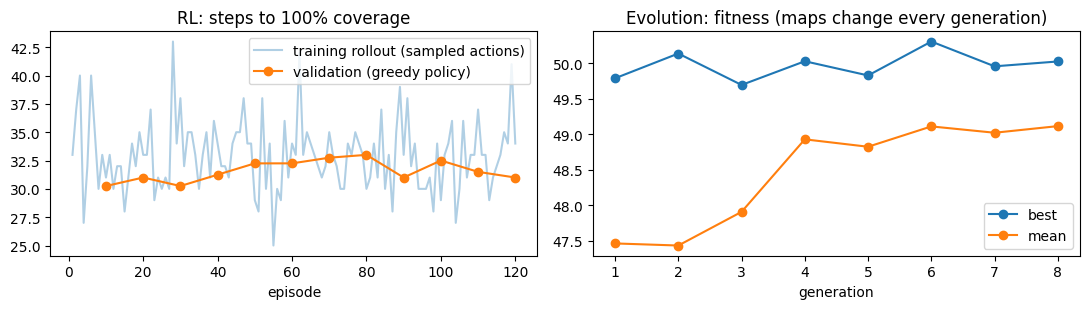

Held-out maps, mean steps to 100% coverage (lower = faster):
  Hungarian (deterministic): 29.0
  RL policy                : 34.0
  EVO policy               : 32.166666666666664


In [22]:
# ---- Learning curves + held-out check (maps never seen in training) ----
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot([r['episode'] for r in rl_results], [r['steps'] for r in rl_results], alpha=.35, label='training rollout (sampled actions)')
val = [(r['episode'], r['val_steps']) for r in rl_results if 'val_steps' in r]
ax[0].plot(*zip(*val), 'o-', label='validation (greedy policy)')
ax[0].set_title('RL: steps to 100% coverage'); ax[0].set_xlabel('episode'); ax[0].legend()
ax[1].plot([h['generation'] for h in evo_policy.fitness_history], [h['best_fitness'] for h in evo_policy.fitness_history], 'o-', label='best')
ax[1].plot([h['generation'] for h in evo_policy.fitness_history], [h['mean_fitness'] for h in evo_policy.fitness_history], 'o-', label='mean')
ax[1].set_title('Evolution: fitness (maps change every generation)'); ax[1].set_xlabel('generation'); ax[1].legend()
plt.tight_layout(); plt.show()

held_out = range(950, 956)
print("Held-out maps, mean steps to 100% coverage (lower = faster):")
print("  Hungarian (deterministic):", evaluate_policy(DeterministicSearch(HungarianFrontierAssignment()), held_out))
print("  RL policy                :", evaluate_policy(rl_policy, held_out))
print("  EVO policy               :", evaluate_policy(evo_policy, held_out))

# 17. Policy Showcases
Runs policies on a hard test map (65x65) containing dynamic hazards and master failure at step 30.

In [23]:
SHOWCASE_CONFIG = SimulationConfig(
  seed=901, width=65, height=65, num_drones=6, num_humans=0, num_animals=0,
  max_steps=200, fail_master_at=30, obstacle_probability=0.03,
  hazards=[
    rect_hazard('Wind zone', 24, 24, 40, 40, move_cost_multiplier=3.0, drain_per_step=0.2),
    fire_hazard([(45, 15), (15, 45)], spread_period=3, seed=7),   # 2 fireplaces, each grows 1 cell every 3 steps
  ],
)

## 17a. Hungarian Frontier Exploration

In [25]:
sim_det = build_simulation(SHOWCASE_CONFIG, policy=DeterministicSearch(HungarianFrontierAssignment())).run()
print("Hungarian:", summarize(sim_det))
show_run(sim_det)

Hungarian: step=133  coverage= 92%  found:   alive=0/6  mean battery=   0%  stop=no_drones_alive  runtime=17.57s


Output()

## 17b. Proximal Policy Optimization (PPO)


In [26]:
rl_policy.training_enabled = False          # pure inference: greedy actions, no learning
sim_rl = build_simulation(SHOWCASE_CONFIG, policy=rl_policy).run()
print("RL:", summarize(sim_rl))
show_run(sim_rl)

RL: step=118  coverage= 98%  found:   alive=0/6  mean battery=   0%  stop=no_drones_alive  runtime=19.45s


Output()

## 17c. Genetic Algorithm (GA)


In [27]:
sim_evo = build_simulation(SHOWCASE_CONFIG, policy=evo_policy).run()
print("EVO:", summarize(sim_evo))
show_run(sim_evo)

EVO: step=132  coverage= 98%  found:   alive=0/6  mean battery=   0%  stop=no_drones_alive  runtime=21.48s


Output()

# 18. Multi-Scenario Benchmarking
Evaluates performance across multi-size maps (30x30 to 100x100) under stress constraints.

In [33]:
# 18a. Run the benchmark ------------------------------------------------------
import pandas as pd

# --- strategies ---------------------------------------------------------------
def _frozen(policy):
  """Learned policies must run in pure inference mode during a benchmark."""
  if hasattr(policy, "training_enabled"):
    policy.training_enabled = False
  return policy

CONTENDERS = {
  "NearestFrontier":   lambda: DeterministicSearch(NearestFrontierAssignment()),
  "Sectors":           lambda: DeterministicSearch(SectorAssignment()),
  "InformationGain":   lambda: DeterministicSearch(InformationGainAssignment()),
  "RiskAware":         lambda: DeterministicSearch(RiskAwareFrontierAssignment()),
  "HumanPriority":     lambda: DeterministicSearch(HumanPriorityAssignment()),
  "HungarianFrontier": lambda: DeterministicSearch(HungarianFrontierAssignment()),
  "RL (trained)":      lambda: _frozen(rl_policy),
  "EVO (trained)":     lambda: _frozen(evo_policy),
}

# --- scenarios ----------------------------------------------------------------
# `stress=True` marks scenarios with fire / wind / master failure (used for the robustness view).
SCENARIOS = {
  "30x30 open": dict(size=30,  density=0.01, seeds=[500, 501, 502, 503, 504], drones=6, humans=5,  animals=2, max_steps=120),
  "30x30 sparse":  dict(size=30,  density=0.10, seeds=[500, 501, 502, 503, 504], drones=6, humans=5,  animals=2, max_steps=120),
  "30x30 dense":   dict(size=30,  density=0.30, seeds=[500, 501, 502, 503, 504], drones=6, humans=5,  animals=2, max_steps=120),
  "30x30 fire + master loss": dict(size=30, density=0.03, seeds=[700, 701, 702, 703, 704], drones=6, humans=5, animals=2, max_steps=150, stress=True),
  "65x65 open": dict(size=65,  density=0.01, seeds=[500, 501, 502, 503, 504], drones=6, humans=5,  animals=2, max_steps=150),
  "65x65 sparse":  dict(size=65,  density=0.10, seeds=[500, 501, 502, 503, 504], drones=6, humans=5,  animals=2, max_steps=150),
  "65x65 dense":   dict(size=65,  density=0.30, seeds=[500, 501, 502, 503, 504], drones=6, humans=5,  animals=2, max_steps=150),
  "65x65 fire + master loss": dict(size=65, density=0.03, seeds=[700, 701, 702, 703, 704], drones=6, humans=5, animals=2, max_steps=180, stress=True),
  "100x100 open":      dict(size=100, density=0.03, seeds=[600, 601, 602],           drones=8, humans=10, animals=4, max_steps=150),
}

def _stress_extras(seed):
  return dict(
    fail_master_at=30,
    hazards=[rect_hazard("Wind zone", 8, 12, 16, 22, move_cost_multiplier=3.0, drain_per_step=0.2),
             fire_hazard([(22, 8), (5, 24)], spread_period=3, seed=seed)])

def make_config(spec, seed):
  extras = _stress_extras(seed) if spec.get("stress") else {}
  return SimulationConfig(seed=seed, width=spec["size"], height=spec["size"], num_drones=spec["drones"],
                          num_humans=spec["humans"], num_animals=spec["animals"], max_steps=spec["max_steps"],
                          obstacle_probability=spec["density"], **extras)

# --- per-run metrics ------------------------------------------------------------
def coverage_curve(sim, horizon):
  """Coverage at steps 0..horizon (stays flat after the run stops)."""
  cov = np.array([s.coverage for s in sim.history], dtype=float)
  if len(cov) < horizon + 1:
    cov = np.pad(cov, (0, horizon + 1 - len(cov)), mode="edge")
  return cov[:horizon + 1]

def benchmark_stats(sim, horizon):
  """simulation_stats + budget-normalised exploration metrics."""
  row = simulation_stats(sim)
  cov = coverage_curve(sim, horizon)
  def t_reach(x):
    hit = np.nonzero(cov >= x)[0]
    return hit[0] / horizon if len(hit) else 1.0           # 1.0 = never reached within the budget
  row.update(
    coverage_auc=float(cov.mean()),
    t50_frac=t_reach(0.5), t90_frac=t_reach(0.9), t100_frac=t_reach(0.999),
    first_human_frac=(row["first_human_step"] / horizon) if row["first_human_step"] is not None else 1.0,
    runtime_per_cov=row["runtime_s"] / max(row["coverage"], 1e-9),
  )
  return row

rows, benchmark_curves = [], {}
for scen_name, spec in SCENARIOS.items():
  print(f"{scen_name}: {len(spec['seeds'])} seeds x {len(CONTENDERS)} strategies", end=" ... ")
  for strat, make in CONTENDERS.items():
    for sd in spec["seeds"]:
      config = make_config(spec, sd)
      # Safety check: scale down entities if there are not enough reachable free cells
      env_test = Environment(config.width, config.height).generate(config.seed, config.obstacle_probability)
      for factory in config.hazards:
        env_test.add_hazard(factory(env_test))
      pathfinder = Pathfinder()
      # base station = free cell closest to bottom-left corner
      free_cells = [Position(y, x) for y in range(env_test.height) for x in range(env_test.width) if env_test.is_free(y, x)]
      if free_cells:
        base = min(free_cells, key=lambda c: (env_test.height - 1 - c.y) + c.x)
        dist, _ = pathfinder.search(env_test.terrain(), base)
        reachable_count = int((dist >= 0).sum())
        # Max entities we can spawn is based strictly on non-damaging free cells in reachable area
        # excluded from base starting slots
        starts_count = min(config.num_drones, reachable_count)
        max_spawns = max(0, reachable_count - starts_count - 2)
        requested = config.num_humans + config.num_animals
        if requested > max_spawns:
          if max_spawns <= 0:
            config = replace(config, num_humans=1 if reachable_count > starts_count else 0, num_animals=0)
          else:
            ratio = max_spawns / max(1, requested)
            h_count = max(1, int(config.num_humans * ratio))
            a_count = int(config.num_animals * ratio)
            if h_count + a_count > max_spawns:
              h_count = max(1, max_spawns - a_count)
              a_count = max_spawns - h_count
            config = replace(config, num_humans=max(0, h_count), num_animals=max(0, a_count))
      sim = build_simulation(config, policy=make()).run()
      rows.append({"strategy": strat, "scenario": scen_name, "stress": bool(spec.get("stress")),
                   "size": spec["size"], "density": spec["density"], "seed": sd,
                   **benchmark_stats(sim, spec["max_steps"])})
      benchmark_curves[(strat, scen_name, sd)] = coverage_curve(sim, spec["max_steps"])
  print("done")

benchmark_runs = pd.DataFrame(rows)
STRATEGIES = list(CONTENDERS)
SCENARIO_NAMES = list(SCENARIOS)

30x30 open: 5 seeds x 8 strategies ... done
30x30 sparse: 5 seeds x 8 strategies ... done
30x30 dense: 5 seeds x 8 strategies ... done
30x30 fire + master loss: 5 seeds x 8 strategies ... done
65x65 open: 5 seeds x 8 strategies ... done
65x65 sparse: 5 seeds x 8 strategies ... done
65x65 dense: 5 seeds x 8 strategies ... done
65x65 fire + master loss: 5 seeds x 8 strategies ... done
100x100 open: 3 seeds x 8 strategies ... done


In [47]:
# 18b. Comparison tables --------------------------------------------------------
# Each metric: (column, label, higher_is_better, aggregation over seeds)
GOALS = {
  "Exploration efficiency": [
    ("coverage_auc", "coverage AUC", True), ("t50_frac", "steps to 50% (frac.)", False),
    ("t90_frac", "steps to 90% (frac.)", False), ("coverage", "final coverage", True),
    ("completed", "completion rate", True)],
  "Coordination quality": [
    ("human_recall", "human recall", True), ("first_human_frac", "first human (frac.)", False),
    ("efficiency_early", "gain/step early", True), ("efficiency_late", "gain/step late", True)],
  "Robustness": [
    ("drones_lost", "drones lost", False), ("worst_cov", "worst-scenario coverage", True),
    ("auc_std", "AUC spread (seeds)", False), ("stress_auc", "AUC fire+master loss", True)],
  "Computational cost": [
    ("decision_ms_mean", "decision ms (mean)", False), ("decision_ms_p95", "decision ms (p95)", False),
    ("runtime_s", "runtime s", False), ("runtime_per_cov", "runtime s / coverage", False)],
}

# per scenario means (each scenario weighs the same, whatever its number of seeds)
scen_mean = benchmark_runs.groupby(["strategy", "scenario"]).mean(numeric_only=True)
overall = scen_mean.groupby("strategy").mean()
overall["worst_cov"] = scen_mean["coverage"].groupby("strategy").min()
overall["auc_std"] = benchmark_runs.groupby(["strategy", "scenario"])["coverage_auc"].std().groupby("strategy").mean()
stress_names = [n for n, s in SCENARIOS.items() if s.get("stress")]
overall["stress_auc"] = scen_mean.xs(stress_names[0], level="scenario")["coverage_auc"] if stress_names else np.nan
overall = overall.loc[STRATEGIES]

def goal_table(goal):
  cols = GOALS[goal]
  t = overall[[c for c, _, _ in cols]].copy()
  t.columns = [lab + (" ↑" if hi else " ↓") for _, lab, hi in cols]
  return t

def style_goal(goal):
  t = goal_table(goal)
  sty = t.style.format("{:.3f}").set_caption(goal + "  (green = best, red = worst per column)")
  for (_, lab, hi) in GOALS[goal]:
    col = lab + (" ↑" if hi else " ↓")
    sty = sty.background_gradient(subset=[col], cmap="RdYlGn" if hi else "RdYlGn_r", axis=0)
  return sty

for g in GOALS:
  display(style_goal(g))

# Per-scenario detail for the most important metrics
def scenario_pivot(metric, fmt="{:.2f}", better_high=True):
  p = scen_mean[metric].unstack("scenario").loc[STRATEGIES, SCENARIO_NAMES]
  return (p.style.format(fmt).background_gradient(cmap="RdYlGn" if better_high else "RdYlGn_r", axis=0)
           .set_caption(metric + " per scenario"))

for m, hi, f in [("coverage_auc", True, "{:.3f}"), ("t90_frac", False, "{:.2f}"),
                 ("human_recall", True, "{:.2f}"), ("decision_ms_mean", False, "{:.2f}")]:
  display(scenario_pivot(m, f, hi))

,coverage AUC ↑,steps to 50% (frac.) ↓,steps to 90% (frac.) ↓,final coverage ↑,completion rate ↑
strategy,,,,,
NearestFrontier,0.654,0.334,0.614,0.868,0.533
Sectors,0.683,0.285,0.614,0.903,0.511
InformationGain,0.754,0.204,0.509,0.947,0.444
RiskAware,0.658,0.339,0.609,0.899,0.356
HumanPriority,0.600,0.398,0.695,0.816,0.400
HungarianFrontier,0.712,0.250,0.569,0.913,0.444
RL (trained),0.764,0.206,0.467,0.959,0.533
EVO (trained),0.763,0.205,0.466,0.957,0.533


,human recall ↑,first human (frac.) ↓,gain/step early ↑,gain/step late ↑
strategy,,,,
NearestFrontier,0.883,0.123,0.019,0.006
Sectors,0.900,0.105,0.019,0.006
InformationGain,0.937,0.095,0.025,0.002
RiskAware,0.905,0.126,0.016,0.006
HumanPriority,0.834,0.123,0.016,0.006
HungarianFrontier,0.916,0.099,0.022,0.004
RL (trained),0.950,0.098,0.025,0.003
EVO (trained),0.941,0.097,0.024,0.004


,drones lost ↓,worst-scenario coverage ↑,AUC spread (seeds) ↓,AUC fire+master loss ↑
strategy,,,,
NearestFrontier,3.311,0.663,0.064,0.916
Sectors,3.556,0.678,0.025,0.900
InformationGain,4.022,0.790,0.027,0.921
RiskAware,3.756,0.635,0.030,0.911
HumanPriority,4.022,0.524,0.078,0.829
HungarianFrontier,3.756,0.701,0.027,0.928
RL (trained),3.400,0.778,0.020,0.926
EVO (trained),3.311,0.759,0.023,0.927


,decision ms (mean) ↓,decision ms (p95) ↓,runtime s ↓,runtime s / coverage ↓
strategy,,,,
NearestFrontier,77.807,184.987,10.317,16.064
Sectors,76.163,188.154,10.324,13.289
InformationGain,137.288,292.178,18.382,20.314
RiskAware,524.679,861.094,69.922,94.275
HumanPriority,102.429,225.350,13.863,22.536
HungarianFrontier,86.237,211.633,11.395,14.086
RL (trained),164.614,303.059,20.505,22.214
EVO (trained),158.543,291.865,20.431,22.289


scenario,30x30 open,30x30 sparse,30x30 dense,30x30 fire + master loss,65x65 open,65x65 sparse,65x65 dense,65x65 fire + master loss,100x100 open
strategy,,,,,,,,,
NearestFrontier,0.892,0.884,0.688,0.916,0.634,0.551,0.384,0.539,0.398
Sectors,0.885,0.872,0.843,0.900,0.650,0.586,0.390,0.606,0.419
InformationGain,0.913,0.891,0.862,0.921,0.761,0.681,0.485,0.698,0.575
RiskAware,0.872,0.871,0.830,0.911,0.585,0.527,0.363,0.599,0.362
HumanPriority,0.863,0.862,0.662,0.829,0.540,0.516,0.376,0.414,0.336
HungarianFrontier,0.910,0.902,0.868,0.928,0.624,0.626,0.454,0.664,0.431
RL (trained),0.916,0.898,0.867,0.926,0.764,0.698,0.472,0.762,0.572
EVO (trained),0.918,0.900,0.865,0.927,0.756,0.696,0.469,0.766,0.569


scenario,30x30 open,30x30 sparse,30x30 dense,30x30 fire + master loss,65x65 open,65x65 sparse,65x65 dense,65x65 fire + master loss,100x100 open
strategy,,,,,,,,,
NearestFrontier,0.21,0.21,0.43,0.16,0.67,0.91,1.00,0.94,1.00
Sectors,0.23,0.26,0.29,0.21,0.67,0.87,1.00,1.00,1.00
InformationGain,0.15,0.20,0.26,0.15,0.47,0.67,1.00,0.73,0.94
RiskAware,0.26,0.23,0.35,0.16,0.76,0.91,1.00,0.82,1.00
HumanPriority,0.28,0.28,0.47,0.36,0.91,0.95,1.00,1.00,1.00
HungarianFrontier,0.15,0.16,0.25,0.12,0.71,0.89,1.00,0.85,1.00
RL (trained),0.14,0.19,0.26,0.13,0.46,0.62,1.00,0.51,0.90
EVO (trained),0.14,0.18,0.26,0.13,0.47,0.63,1.00,0.49,0.91


scenario,30x30 open,30x30 sparse,30x30 dense,30x30 fire + master loss,65x65 open,65x65 sparse,65x65 dense,65x65 fire + master loss,100x100 open
strategy,,,,,,,,,
NearestFrontier,1.00,1.00,0.75,1.00,1.00,1.00,0.80,0.76,0.63
Sectors,0.96,1.00,1.00,1.00,1.00,0.96,0.76,0.72,0.70
InformationGain,1.00,1.00,1.00,1.00,1.00,0.92,0.72,0.96,0.83
RiskAware,1.00,1.00,1.00,1.00,0.96,0.88,0.72,0.92,0.67
HumanPriority,1.00,1.00,0.75,0.84,0.92,1.00,0.76,0.60,0.63
HungarianFrontier,1.00,1.00,1.00,1.00,0.96,0.92,0.68,0.88,0.80
RL (trained),1.00,1.00,1.00,0.96,1.00,1.00,0.80,0.96,0.83
EVO (trained),1.00,1.00,1.00,1.00,1.00,0.96,0.64,1.00,0.87


scenario,30x30 open,30x30 sparse,30x30 dense,30x30 fire + master loss,65x65 open,65x65 sparse,65x65 dense,65x65 fire + master loss,100x100 open
strategy,,,,,,,,,
NearestFrontier,19.93,17.00,11.00,13.45,108.47,82.91,50.17,63.85,333.49
Sectors,16.84,14.75,7.16,10.06,106.19,81.04,50.44,66.02,332.96
InformationGain,25.30,21.34,13.73,24.32,158.52,139.39,105.68,119.40,627.90
RiskAware,148.84,119.52,58.34,105.98,691.34,520.31,307.36,554.26,2216.16
HumanPriority,23.36,20.96,9.32,15.94,125.90,103.07,68.33,77.74,477.25
HungarianFrontier,21.47,19.49,12.13,21.11,114.21,91.18,63.63,86.91,346.00
RL (trained),81.76,40.63,20.03,45.77,185.31,154.35,109.41,150.69,693.57
EVO (trained),37.50,34.75,22.46,40.57,183.39,154.89,109.15,149.12,695.06


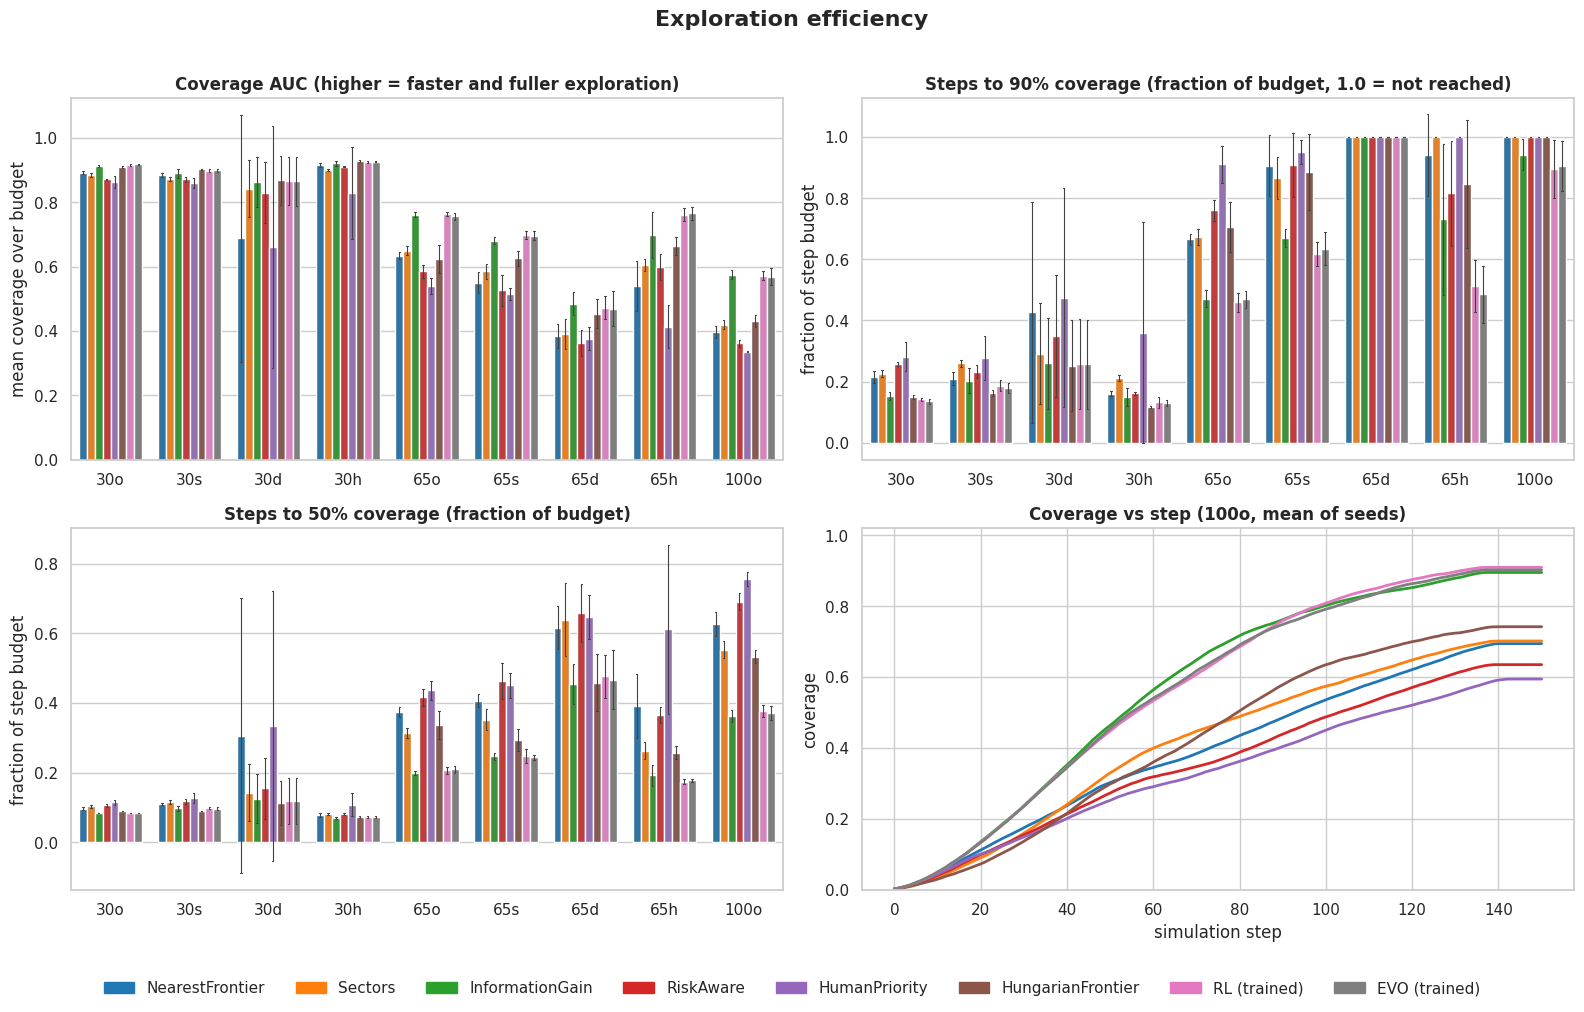

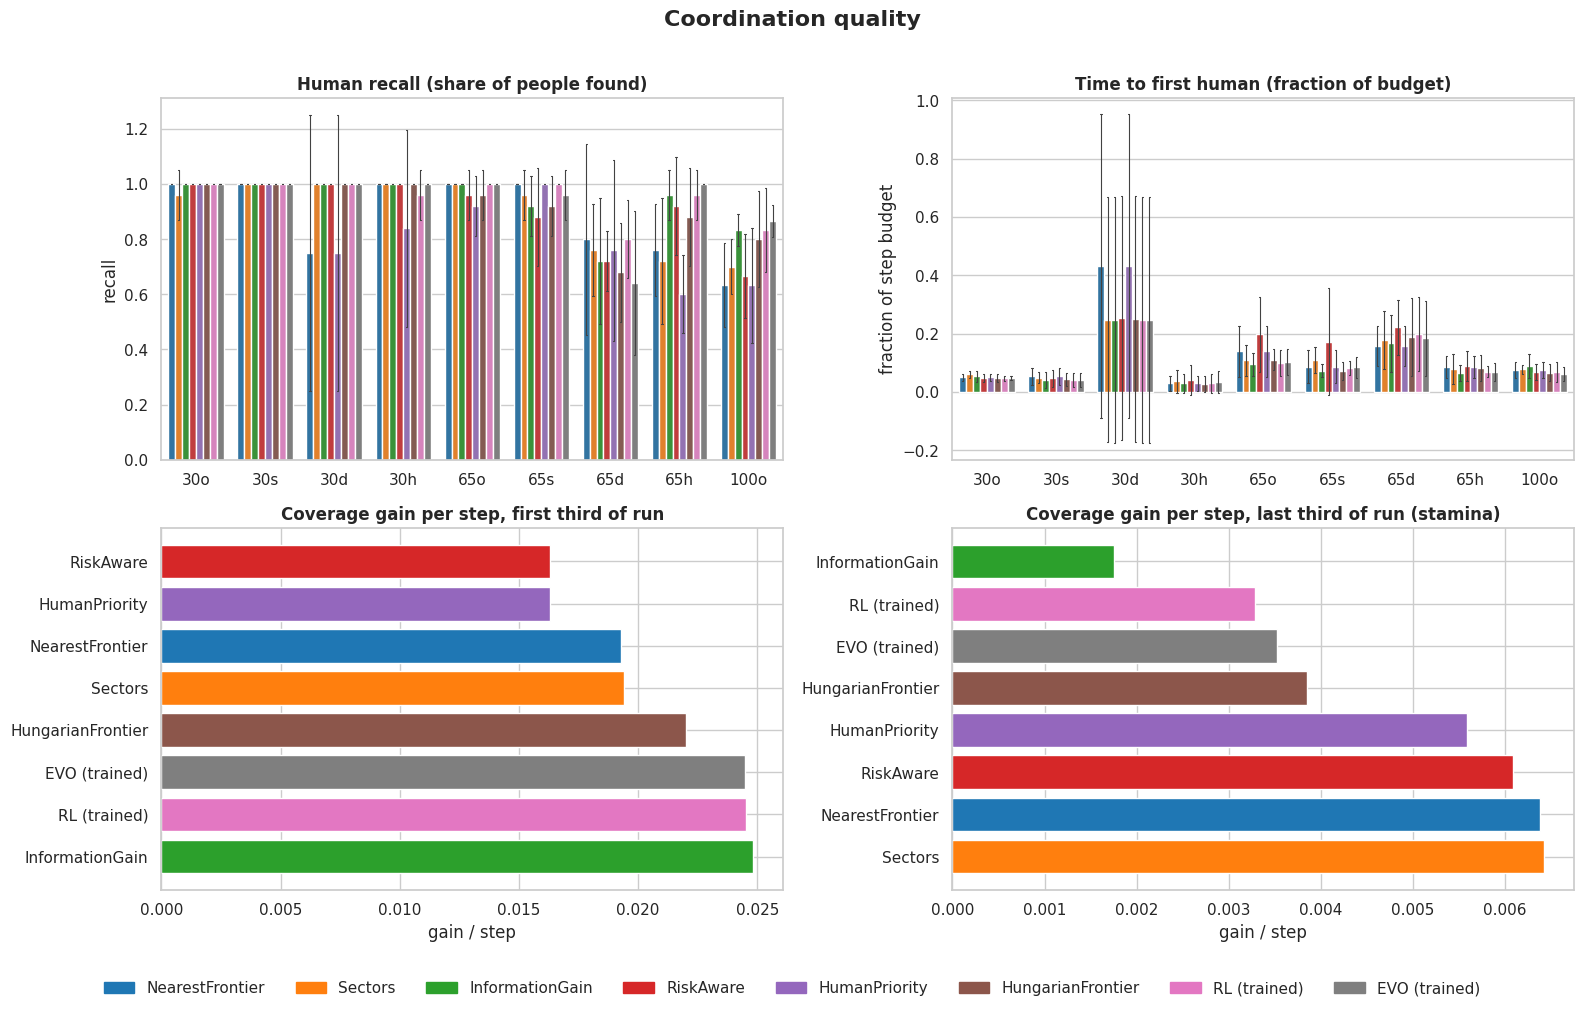

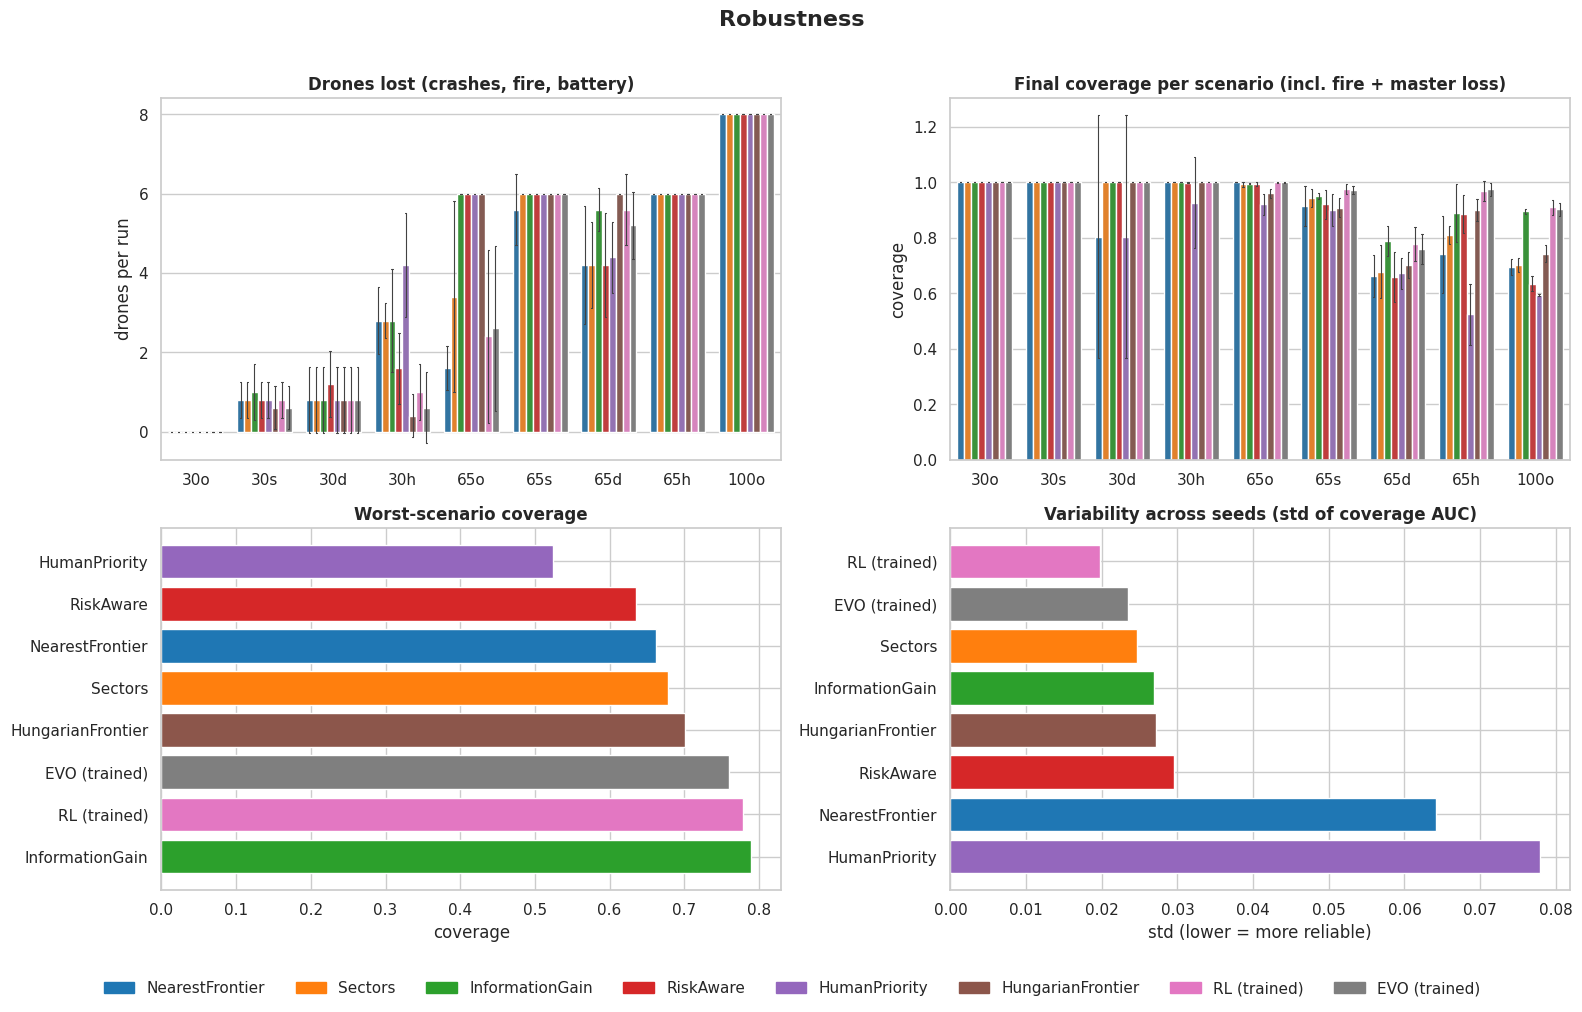

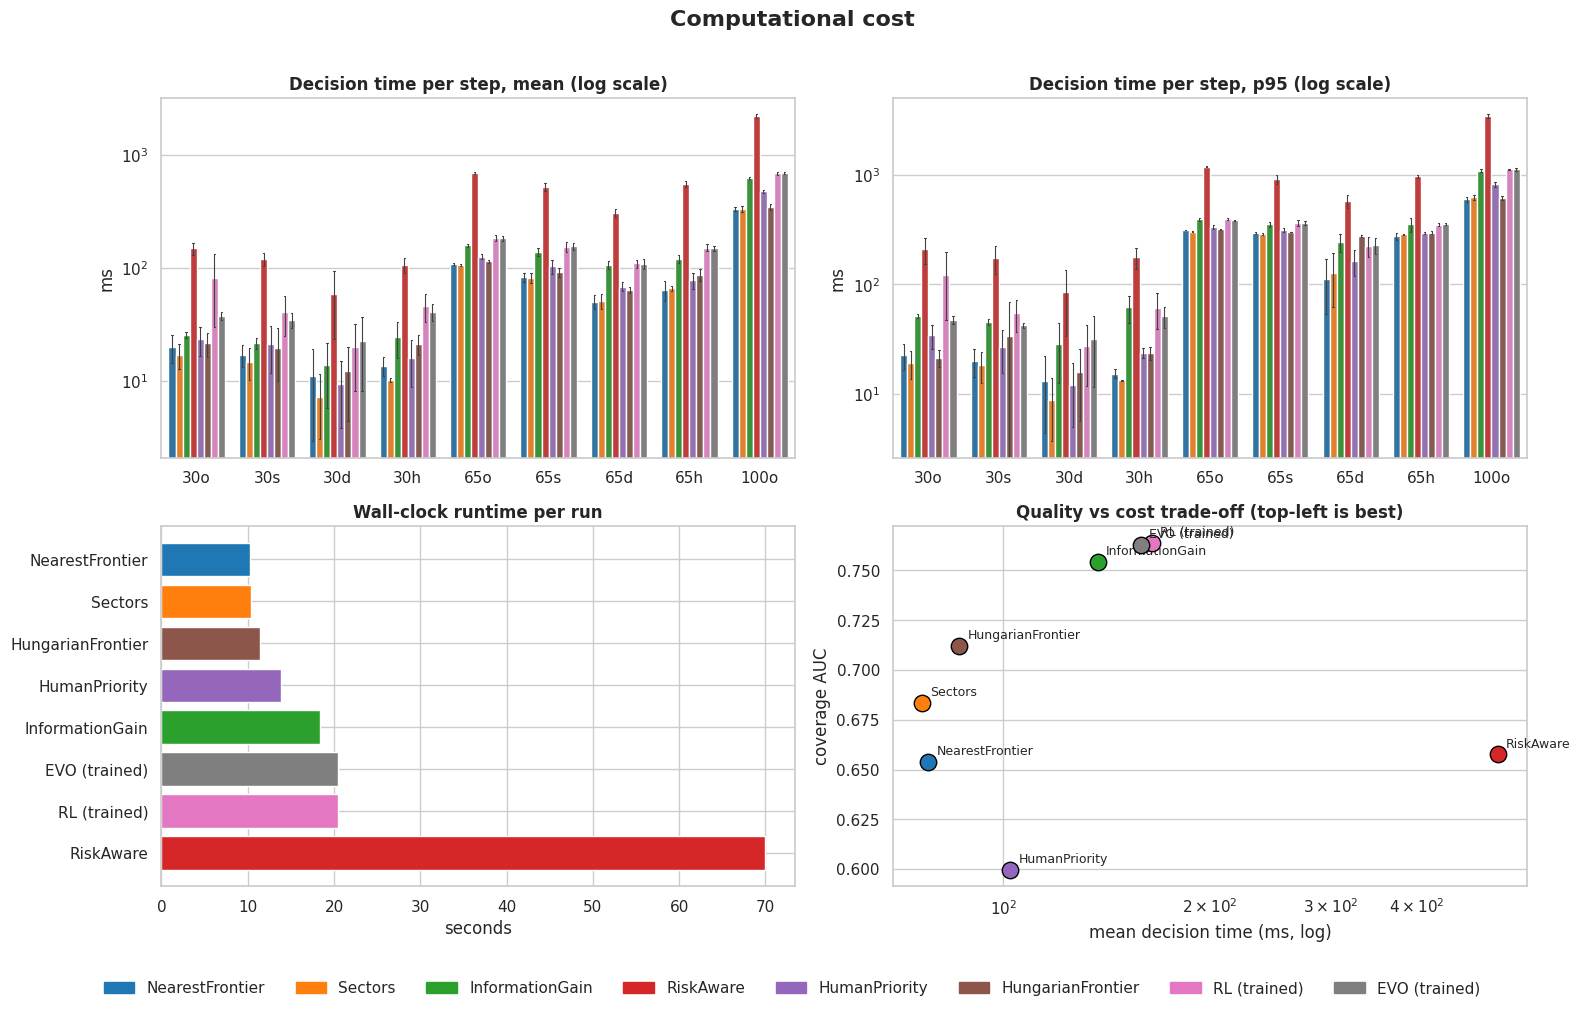

In [41]:
# 18c-f. Plots, one figure per goal --------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = dict(zip(STRATEGIES, sns.color_palette("tab10", len(STRATEGIES))))

# Map from long scenario names to compact versions
COMPACT_MAP = {
  "30x30 open": "30o",
  "30x30 sparse": "30s",
  "30x30 dense": "30d",
  "30x30 fire + master loss": "30h",
  "65x65 open": "65o",
  "65x65 sparse": "65s",
  "65x65 dense": "65d",
  "65x65 fire + master loss": "65h",
  "100x100 open": "100o"
}

# Create a copy of the dataframe with compact labels for plotting
compact_runs = benchmark_runs.copy()
compact_runs["scenario"] = compact_runs["scenario"].map(COMPACT_MAP)
COMPACT_ORDER = [COMPACT_MAP[name] for name in SCENARIO_NAMES if name in COMPACT_MAP]

def bar_by_scenario(ax, metric, title, ylabel, log=False):
  sns.barplot(data=compact_runs, x="scenario", y=metric, hue="strategy", hue_order=STRATEGIES,
              order=COMPACT_ORDER, palette=PALETTE, errorbar="sd", capsize=0.15, err_kws={"linewidth": 0.8}, ax=ax)
  ax.set_title(title, fontweight="bold"); ax.set_ylabel(ylabel); ax.set_xlabel("")
  ax.tick_params(axis="x", rotation=0) # Compact enough to remain horizontal!
  if log: ax.set_yscale("log")
  if ax.get_legend(): ax.get_legend().remove()

def bar_overall(ax, metric, title, xlabel, log=False):
  vals = overall[metric].sort_values(ascending=metric not in ("coverage", "human_recall", "coverage_auc"))
  ax.barh(vals.index, vals.values, color=[PALETTE[s] for s in vals.index])
  ax.set_title(title, fontweight="bold"); ax.set_xlabel(xlabel); ax.invert_yaxis()
  if log: ax.set_xscale("log")

def shared_legend(fig):
  handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[s]) for s in STRATEGIES]
  fig.legend(handles, STRATEGIES, loc="lower center", ncol=len(STRATEGIES), frameon=False, bbox_to_anchor=(0.5, -0.02))

# ---- 18c. Exploration efficiency ----
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
bar_by_scenario(axes[0, 0], "coverage_auc", "Coverage AUC (higher = faster and fuller exploration)", "mean coverage over budget")
bar_by_scenario(axes[0, 1], "t90_frac", "Steps to 90% coverage (fraction of budget, 1.0 = not reached)", "fraction of step budget")
bar_by_scenario(axes[1, 0], "t50_frac", "Steps to 50% coverage (fraction of budget)", "fraction of step budget")
# coverage-vs-step curves, averaged over seeds, one line per strategy, on the hardest-to-finish map
curve_scen = "100x100 open" if "100x100 open" in SCENARIOS else SCENARIO_NAMES[0]
H = SCENARIOS[curve_scen]["max_steps"]
for s in STRATEGIES:
  c = np.mean([benchmark_curves[(s, curve_scen, sd)] for sd in SCENARIOS[curve_scen]["seeds"]], axis=0)
  axes[1, 1].plot(np.arange(H + 1), c, color=PALETTE[s], lw=2, label=s)
axes[1, 1].set_title(f"Coverage vs step ({COMPACT_MAP.get(curve_scen, curve_scen)}, mean of seeds)", fontweight="bold")
axes[1, 1].set_xlabel("simulation step"); axes[1, 1].set_ylabel("coverage"); axes[1, 1].set_ylim(0, 1.02)
fig.suptitle("Exploration efficiency", fontsize=16, fontweight="bold"); shared_legend(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()

# ---- 18d. Coordination quality ----
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
bar_by_scenario(axes[0, 0], "human_recall", "Human recall (share of people found)", "recall")
bar_by_scenario(axes[0, 1], "first_human_frac", "Time to first human (fraction of budget)", "fraction of step budget")
bar_overall(axes[1, 0], "efficiency_early", "Coverage gain per step, first third of run", "gain / step")
bar_overall(axes[1, 1], "efficiency_late", "Coverage gain per step, last third of run (stamina)", "gain / step")
fig.suptitle("Coordination quality", fontsize=16, fontweight="bold"); shared_legend(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()

# ---- 18e. Robustness ----
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
bar_by_scenario(axes[0, 0], "drones_lost", "Drones lost (crashes, fire, battery)", "drones per run")
bar_by_scenario(axes[0, 1], "coverage", "Final coverage per scenario (incl. fire + master loss)", "coverage")
bar_overall(axes[1, 0], "worst_cov", "Worst-scenario coverage", "coverage")
bar_overall(axes[1, 1], "auc_std", "Variability across seeds (std of coverage AUC)", "std (lower = more reliable)")
fig.suptitle("Robustness", fontsize=16, fontweight="bold"); shared_legend(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()

# ---- 18f. Computational cost ----
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
bar_by_scenario(axes[0, 0], "decision_ms_mean", "Decision time per step, mean (log scale)", "ms", log=True)
bar_by_scenario(axes[0, 1], "decision_ms_p95", "Decision time per step, p95 (log scale)", "ms", log=True)
bar_overall(axes[1, 0], "runtime_s", "Wall-clock runtime per run", "seconds")
ax = axes[1, 1]
for s in STRATEGIES:
  ax.scatter(overall.loc[s, "decision_ms_mean"], overall.loc[s, "coverage_auc"], s=140, color=PALETTE[s], edgecolor="black", zorder=3)
  ax.annotate(s, (overall.loc[s, "decision_ms_mean"], overall.loc[s, "coverage_auc"]), xytext=(6, 5), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("mean decision time (ms, log)"); ax.set_ylabel("coverage AUC")
ax.set_title("Quality vs cost trade-off (top-left is best)", fontweight="bold")
fig.suptitle("Computational cost", fontsize=16, fontweight="bold"); shared_legend(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()

,Exploration efficiency,Coordination quality,Robustness,Computational cost,Overall (equal weights)
strategy,,,,,
EVO (trained),0.99,0.80,0.95,0.68,0.86
RL (trained),1.00,0.80,0.95,0.66,0.85
HungarianFrontier,0.63,0.68,0.73,0.94,0.75
InformationGain,0.83,0.72,0.70,0.72,0.74
Sectors,0.59,0.66,0.72,1.00,0.74
NearestFrontier,0.48,0.46,0.66,0.97,0.64
RiskAware,0.32,0.39,0.61,0.00,0.33
HumanPriority,0.05,0.23,0.00,0.82,0.28


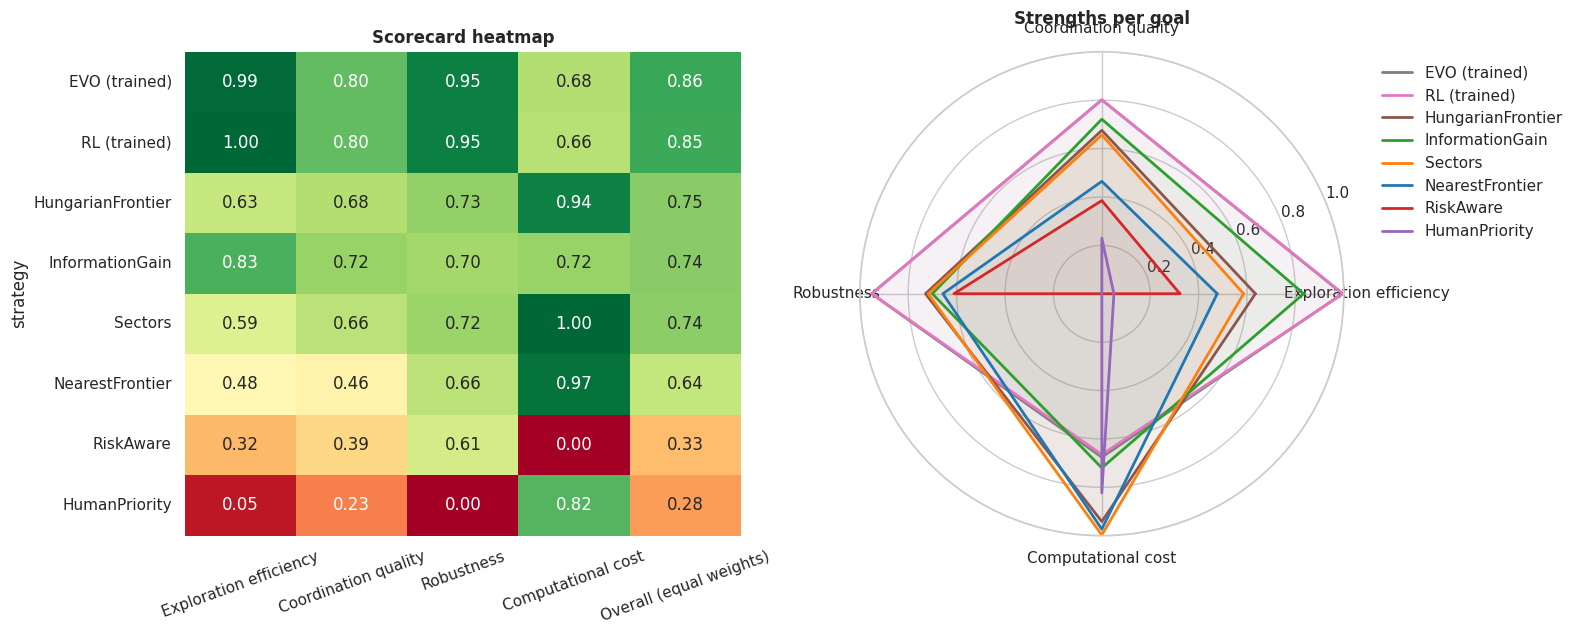

In [39]:
# 18g. Overall scorecard --------------------------------------------------------
# Every metric is min-max scaled across strategies to 0 (worst) .. 1 (best); a goal score is the mean of its metrics.
# Cost metrics are log-scaled first because they span orders of magnitude.
LOG_METRICS = {"decision_ms_mean", "decision_ms_p95", "runtime_s", "runtime_per_cov"}

def _scaled(col, higher_is_better):
  v = overall[col].astype(float)
  v = np.log10(v.clip(lower=1e-9)) if col in LOG_METRICS else v
  rng = v.max() - v.min()
  s = (v - v.min()) / rng if rng > 0 else pd.Series(0.5, index=v.index)
  return s if higher_is_better else 1 - s

scores = pd.DataFrame({g: pd.concat([_scaled(c, hi) for c, _, hi in cols], axis=1).mean(axis=1)
                       for g, cols in GOALS.items()}).loc[STRATEGIES]
scores["Overall (equal weights)"] = scores.mean(axis=1)
scores = scores.sort_values("Overall (equal weights)", ascending=False)
display(scores.style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("Scorecard: 0 = worst strategy, 1 = best strategy on each goal"))

goal_cols = list(GOALS)
fig = plt.figure(figsize=(16, 6.5))
ax = fig.add_subplot(1, 2, 1)
sns.heatmap(scores, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title("Scorecard heatmap", fontweight="bold"); ax.tick_params(axis="x", rotation=20)

ax = fig.add_subplot(1, 2, 2, projection="polar")
angles = np.linspace(0, 2 * np.pi, len(goal_cols), endpoint=False).tolist()
for s in scores.index:
  v = scores.loc[s, goal_cols].tolist()
  ax.plot(angles + angles[:1], v + v[:1], color=PALETTE[s], lw=2, label=s)
  ax.fill(angles + angles[:1], v + v[:1], color=PALETTE[s], alpha=0.05)
ax.set_xticks(angles); ax.set_xticklabels(goal_cols); ax.set_ylim(0, 1)
ax.set_title("Strengths per goal", fontweight="bold", pad=20)
ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1.0), frameon=False)
fig.tight_layout(); plt.show()